## Idea

I want to asses whether the proposed architecture from Martijn et al. is a sound way to reconstruct missing data for systems with dynamics that follow a predictable pattern.

This is a version that implements the techniques at a smallers sqale compared to what has implemented elsewhere in the repo, for demonstration purposes.

## Data

One minute of a single BIDMC record :

- **Patient 25, 45–105 s of the record.** The minute was picked by scanning the D1 training patients for 60 s windows with no ECG clipping, no flat PPG stretches and a stable PPG amplitude; of the windows that passed, this one had the most regular beats in both channels.
- **125 Hz, two channels:** ECG lead II (`ecg`) and PPG (`ppg`, PLETH). The demos fill gaps in one channel; the other can act as the helper.
- **Split of the minute:**
  - the first 40 s are the **history**. The recurrence fill searches it for donors;
  - the last 20 s are the **demo window**. Gaps will be cut there, and every method is scored on it.

  Bousse et al.'s completion uses only the demo window: their method needs no history.
- **Scaling:** both channels are z-scored with the mean and standard deviation of the history only, as in D1, so the demo window does not leak into the scaling.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FS = 125 # native dataset hz rate
START_S = 45 # clean, regular minute (see markdown above)
history_split = 40       # library for the recurrence fill
demo_split = 20          # window where gaps are cut and scored

raw = pd.read_csv("../../data/raw/bidmc/bidmc_25_Signals.csv")
raw.columns = [c.strip() for c in raw.columns]   # BIDMC headers have leading spaces

i0 = START_S * FS
n_hist, n_demo = history_split * FS, demo_split * FS
chunk = raw.iloc[i0 : i0 + n_hist + n_demo]
t = chunk["Time [s]"].to_numpy()
x_raw = chunk[["II", "PLETH"]].to_numpy(float)   # columns: 0 = ECG, 1 = PPG
assert len(x_raw) == 7500 and t[0] == 45.0 and t[-1] == 104.99 and np.isfinite(x_raw).all()

In [2]:
# z-score with the history only
mu, sd = x_raw[:n_hist].mean(axis=0), x_raw[:n_hist].std(axis=0)
x = (x_raw - mu) / sd
ecg, ppg = x[:, 0], x[:, 1]

hist = slice(0, n_hist)
demo = slice(n_hist, n_hist + n_demo)
print(f"patient 25: {len(x)} samples = {len(x) / FS:.0f} s at {FS} Hz "
      f"({t[0]:.0f}-{t[-1]:.0f} s of the record)")
print(f"history: {n_hist} samples, demo window: {n_demo} samples")

patient 25: 7500 samples = 60 s at 125 Hz (45-105 s of the record)
history: 5000 samples, demo window: 2500 samples


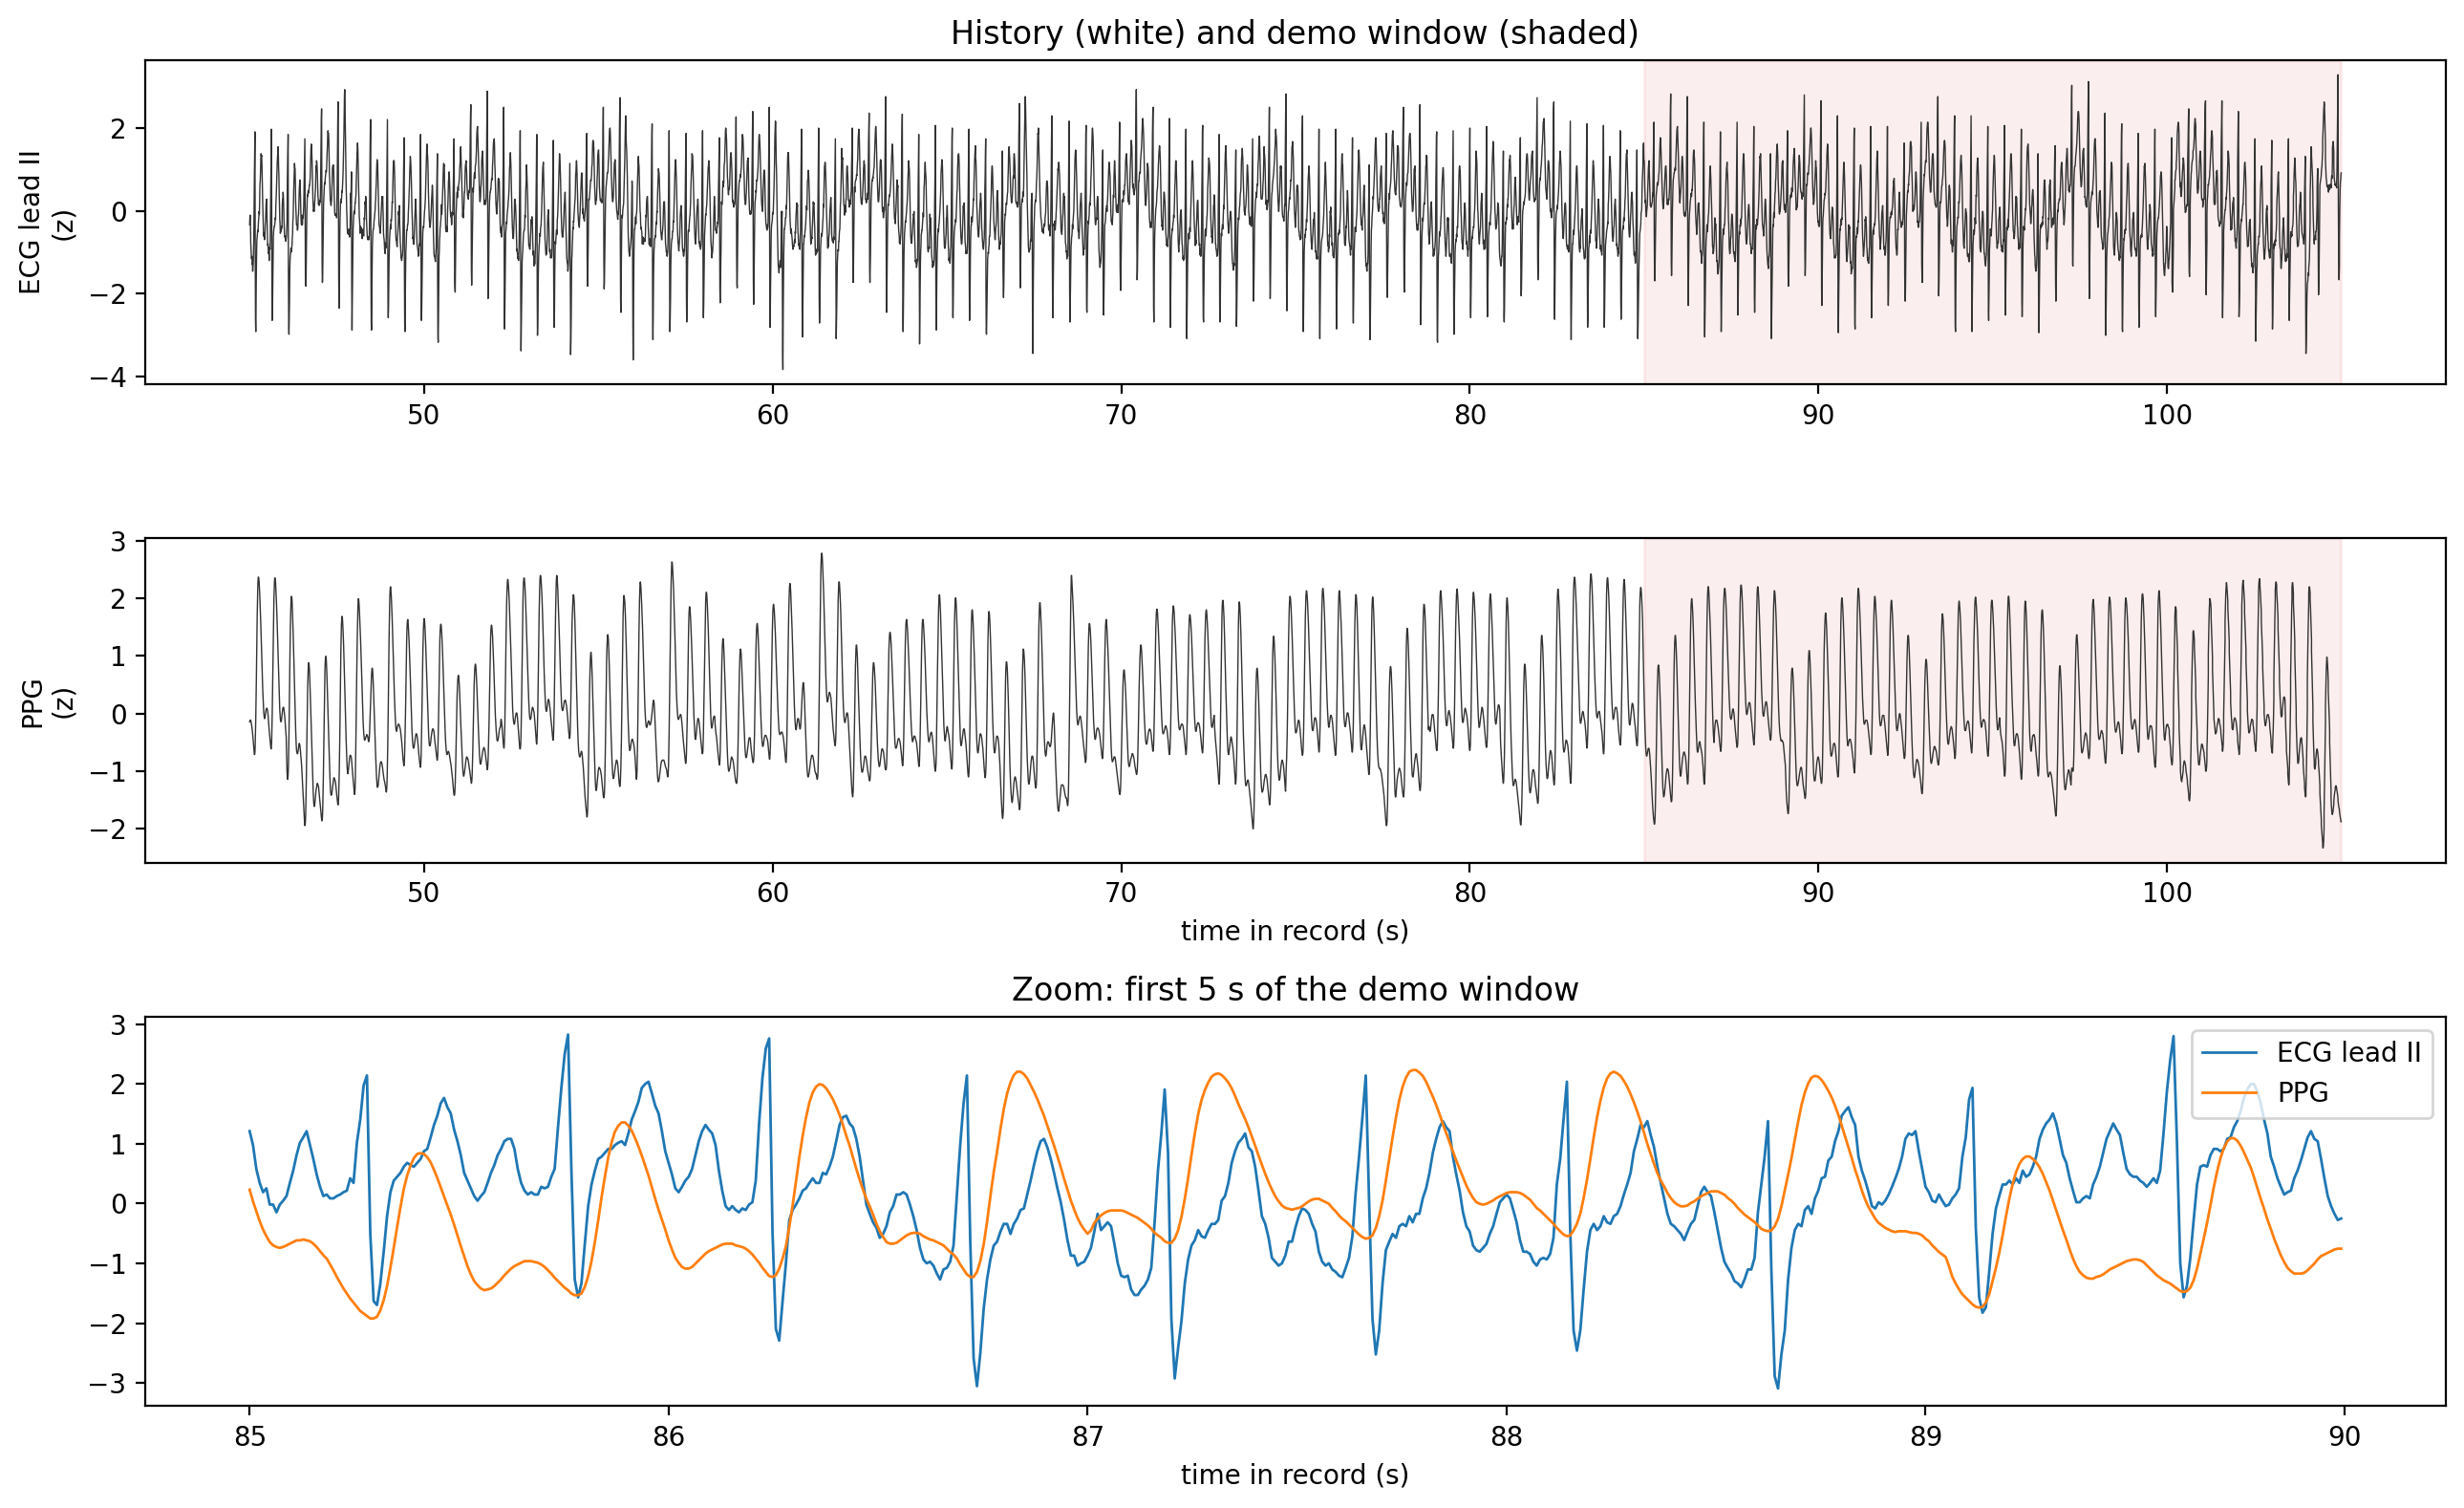

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [1, 1, 1.2]})
for ax, sig, name in [(axes[0], ecg, "ECG lead II"), (axes[1], ppg, "PPG")]:
    ax.plot(t, sig, lw=0.5, color="0.2")
    ax.axvspan(t[demo][0], t[-1], color="tab:red", alpha=0.08)
    ax.set_ylabel(f"{name}\n(z)")
axes[0].set_title("History (white) and demo window (shaded)")
axes[1].set_xlabel("time in record (s)")

# 5 s zoom at the start of the demo window: ECG and PPG together
z = slice(n_hist, n_hist + 5 * FS)
axes[2].plot(t[z], ecg[z], lw=1, label="ECG lead II")
axes[2].plot(t[z], ppg[z], lw=1, label="PPG")
axes[2].set_title("Zoom: first 5 s of the demo window")
axes[2].set_xlabel("time in record (s)")
axes[2].legend(loc="upper right")
fig.tight_layout()
plt.show()

In [4]:
# Gaps are cut in one channel only; the other channel stays complete (helper).
target = 0   # 0 = ECG, 1 = PPG

# (start, length) in samples, counted from the start of the demo window.
# Lengths 25 and 75 are the D1 ECG gap lengths (0.2 s and 0.6 s).
# All gaps stay at least 125 samples (1 s) away from the window edges.
gaps = [(300, 25), (800, 75), (1400, 25), (1900, 75)]

In [5]:
x_obs = x.copy()
missing = np.zeros(len(x), dtype=bool)

for start, length in gaps:
    a = n_hist + start
    b = a + length
    missing[a:b] = True

x_obs[missing, target] = np.nan

print(f"removed {missing.sum()} samples of channel {target} "
      f"({missing.sum() / n_demo:.1%} of the demo window)")

removed 200 samples of channel 0 (8.0% of the demo window)


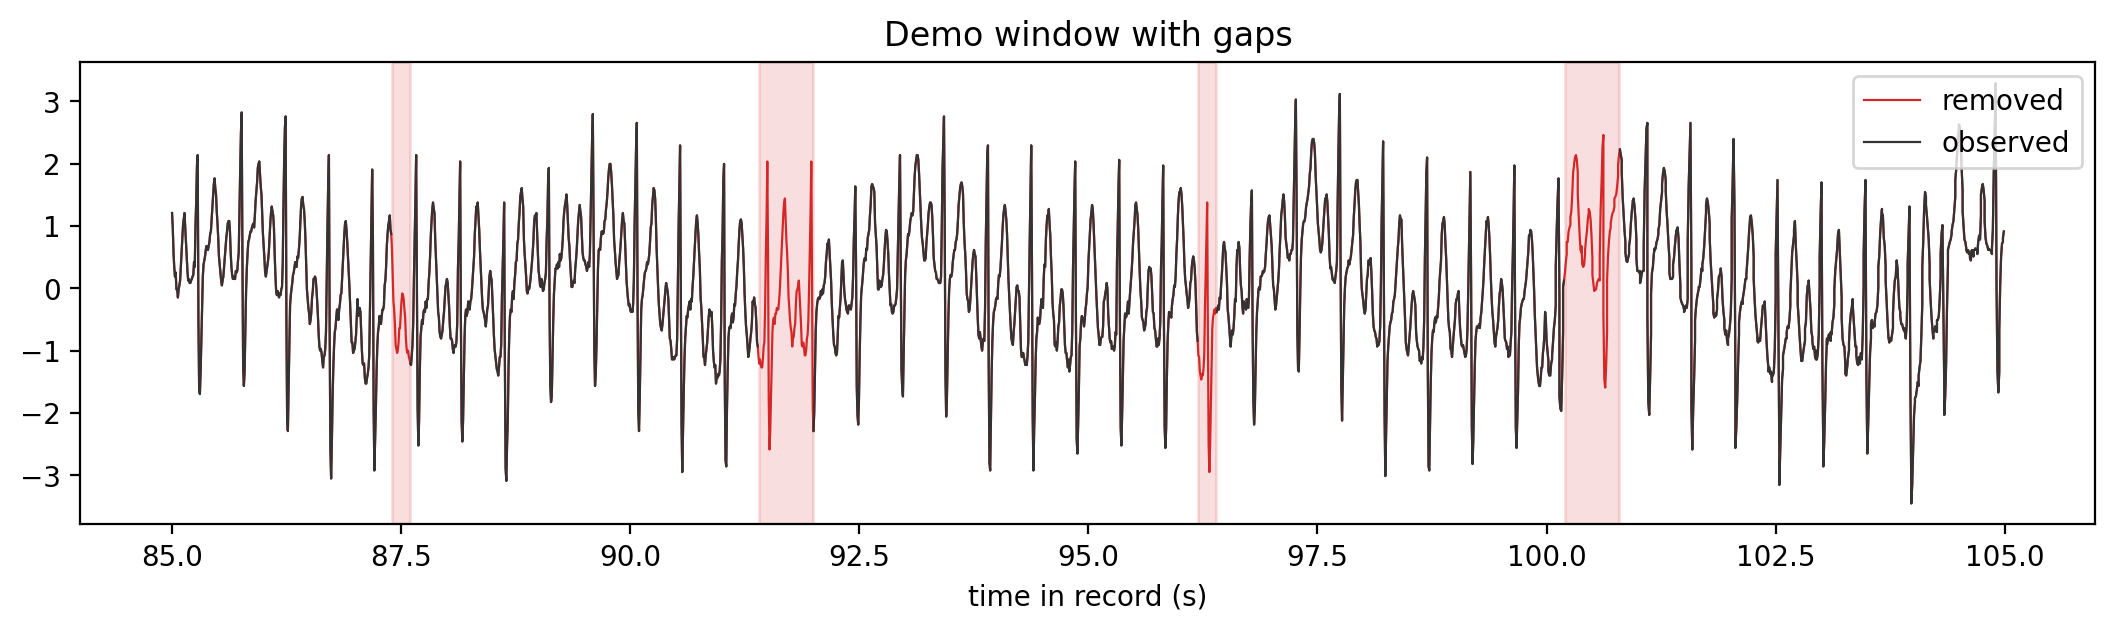

In [6]:
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(t[demo], x[demo, target], color="tab:red", lw=0.8, label="removed")
ax.plot(t[demo], x_obs[demo, target], color="0.2", lw=0.8, label="observed")
for start, length in gaps:
    ax.axvspan(t[n_hist + start], t[n_hist + start + length - 1], color="tab:red", alpha=0.15)
ax.set_title("Demo window with gaps")
ax.set_xlabel("time in record (s)")
ax.legend(loc="upper right")
plt.show()

In [7]:
from scipy.spatial.distance import cdist

# RP embedding used to score every method
RP_M, RP_TAU = 5, 8

def embed(v, m=RP_M, tau=RP_TAU):
    n = len(v) - (m - 1) * tau
    return np.column_stack([v[k * tau : k * tau + n] for k in range(m)])

def unthresholded_rp(v):
    e = embed(v)
    return cdist(e, e)

In [8]:
truth = x[demo, target]
gap_mask = missing[demo]
rp_truth = unthresholded_rp(truth)

results = {}

def score(name, filled):
    mae = np.abs(filled[gap_mask] - truth[gap_mask]).mean()
    rp_err = np.linalg.norm(unthresholded_rp(filled) - rp_truth) / np.linalg.norm(rp_truth)
    results[name] = {"MAE": mae, "RP error": rp_err}
    
    print(f"{name}: MAE {mae:.3f}, RP error {rp_err:.4f}")

In [9]:
from matplotlib.colors import ListedColormap

RP_SEG = (600, 1075)   # segment of the demo window shown in the RP plots (around the gap at 800)
RR = 0.10              # threshold = distance below which 10 % of the truth's pairs fall

# overlap colours: 0 = no recurrence, 1 = in both, 2 = only in truth (missed), 3 = only in fill (spurious)
overlap_cmap = ListedColormap(["white", "black", "tab:red", "tab:blue"])


# def plot_rp_comparison(name, filled):
#     s0, s1 = RP_SEG
#     d_true = unthresholded_rp(truth[s0:s1])
#     d_fill = unthresholded_rp(filled[s0:s1])
#     eps = np.quantile(d_true, RR)          # same threshold for both RPs
#     r_true = d_true <= eps
#     r_fill = d_fill <= eps

#     overlap = np.zeros(r_true.shape, dtype=int)
#     overlap[r_true & r_fill] = 1
#     overlap[r_true & ~r_fill] = 2
#     overlap[~r_true & r_fill] = 3

#     n = len(r_true)
#     extent = (s0, s0 + n, s0, s0 + n)      # axes in sample index of the demo window
#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))
#     axes[0].imshow(r_true, cmap="binary", origin="lower", extent=extent, interpolation="nearest")
#     axes[0].set_title("RP of the original segment")
#     axes[1].imshow(r_fill, cmap="binary", origin="lower", extent=extent, interpolation="nearest")
#     axes[1].set_title(f"RP of the reconstruction ({name})")
#     axes[2].imshow(overlap, cmap=overlap_cmap, vmin=0, vmax=3, origin="lower", extent=extent, interpolation="nearest")
#     axes[2].set_title("Overlap: black both, red missed, blue spurious")
#     for ax in axes:
#         for start, length in gaps:
#             if s0 <= start < s1:
#                 for edge in (start, start + length):
#                     ax.axvline(edge, color="tab:orange", lw=0.8, ls="--")
#                     ax.axhline(edge, color="tab:orange", lw=0.8, ls="--")
#         ax.set_xlabel("sample (demo window)")
#     fig.tight_layout()
#     plt.show()

#     print(f"{name}: {(r_true & r_fill).sum() / r_true.sum():.1%} of the original recurrences kept, "
#           f"{(~r_true & r_fill).sum() / r_fill.sum():.1%} of the reconstruction's recurrences spurious")

In [10]:
# The three RP panels of the dynimp live dashboard (src/dynimp/live_dashboard.py):
# original, reconstruction, and joint (recurrent in both), all binary with the same epsilon.
# As in the dashboard: the segment is z-scored with the original's mean and std, and epsilon is
# chosen so that the original has a recurrence rate of 5 % (diagonal excluded).
DASH_RR = 0.05


def plot_rp_comparison(name, filled, seg=RP_SEG):
    s0, s1 = seg
    mu, sd = truth[s0:s1].mean(), truth[s0:s1].std()
    d_true = unthresholded_rp((truth[s0:s1] - mu) / sd)
    d_fill = unthresholded_rp((filled[s0:s1] - mu) / sd)
    off_diag = ~np.eye(len(d_true), dtype=bool)
    eps = np.quantile(d_true[off_diag], DASH_RR)

    r_true = d_true <= eps
    r_fill = d_fill <= eps
    joint = r_true & r_fill
    rp_err = np.linalg.norm(d_fill - d_true) / np.linalg.norm(d_true)

    n = len(r_true)
    extent = (s0, s0 + n, s0, s0 + n)
    panels = [(r_true, "original system"),
              (r_fill, name),
              (joint, f"joint plot ~ {joint.sum() / r_true.sum():.1%} of original")]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (img, title) in zip(axes, panels):
        ax.imshow(img, cmap="summer", vmin=0, vmax=1, origin="lower", extent=extent, interpolation="nearest")
        ax.set_title(title)
        ax.set_xlabel("sample (demo window)")
    fig.suptitle(f"{name} - RP error {rp_err:.4f}  (epsilon {eps:.3f}, embedding m={RP_M}, tau={RP_TAU})")
    fig.tight_layout()
    plt.show()

In [11]:
obs = x_obs[demo, target] # demo window with NaN in the gaps
idx = np.arange(n_demo)
known = ~np.isnan(obs)

linear_fill = obs.copy()
linear_fill[~known] = np.interp(idx[~known], idx[known], obs[known])

score("linear", linear_fill)

linear: MAE 1.003, RP error 0.1700


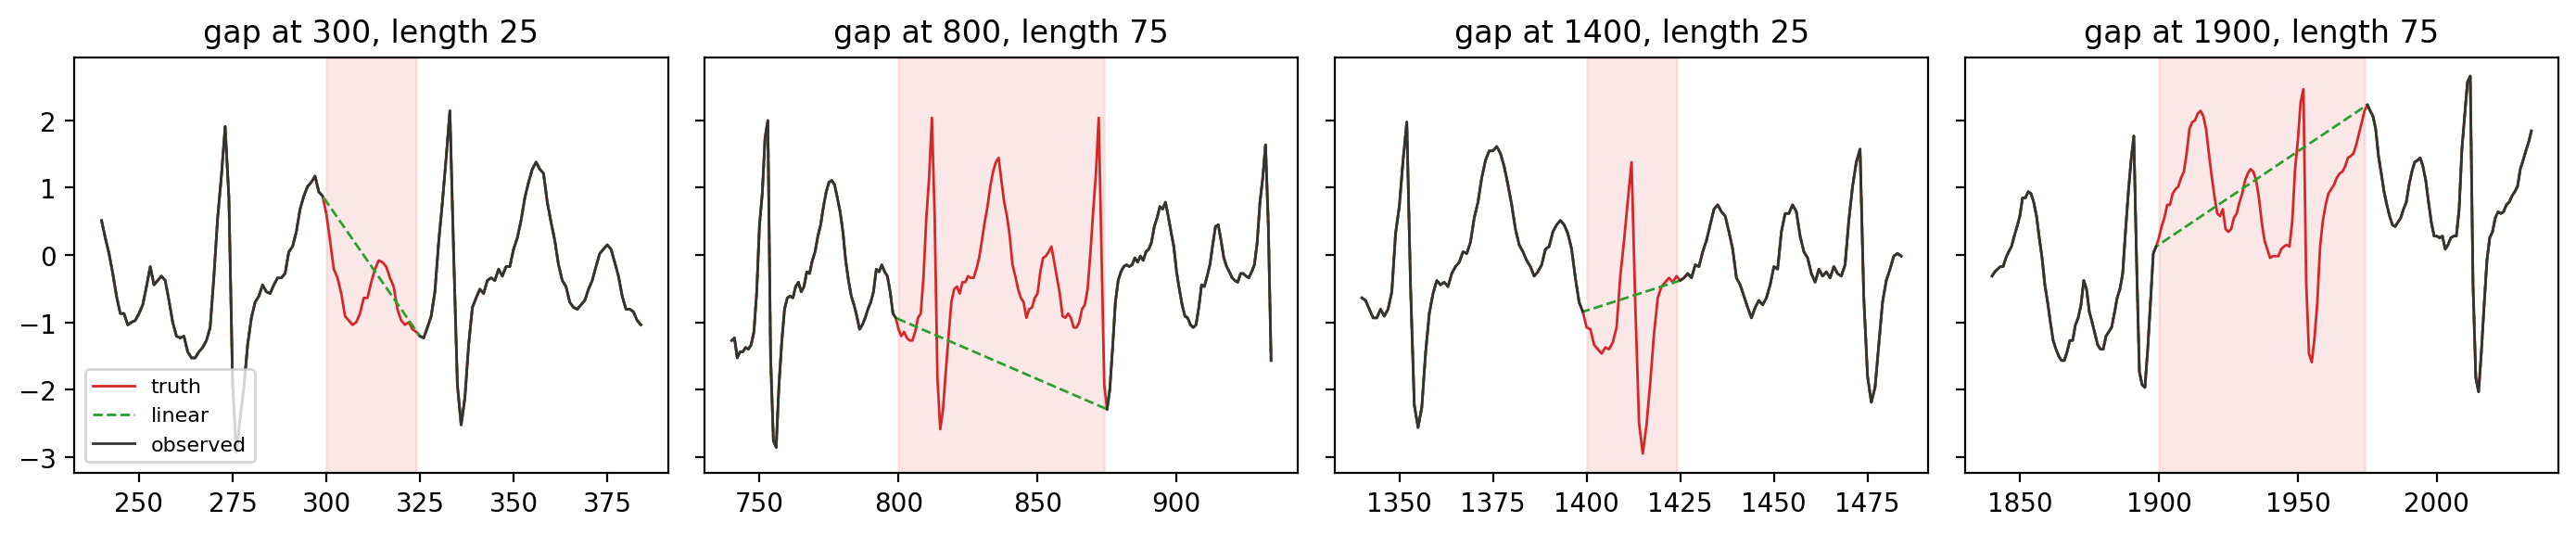

In [12]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], linear_fill[w], color="tab:green", lw=1, ls="--", label="linear")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

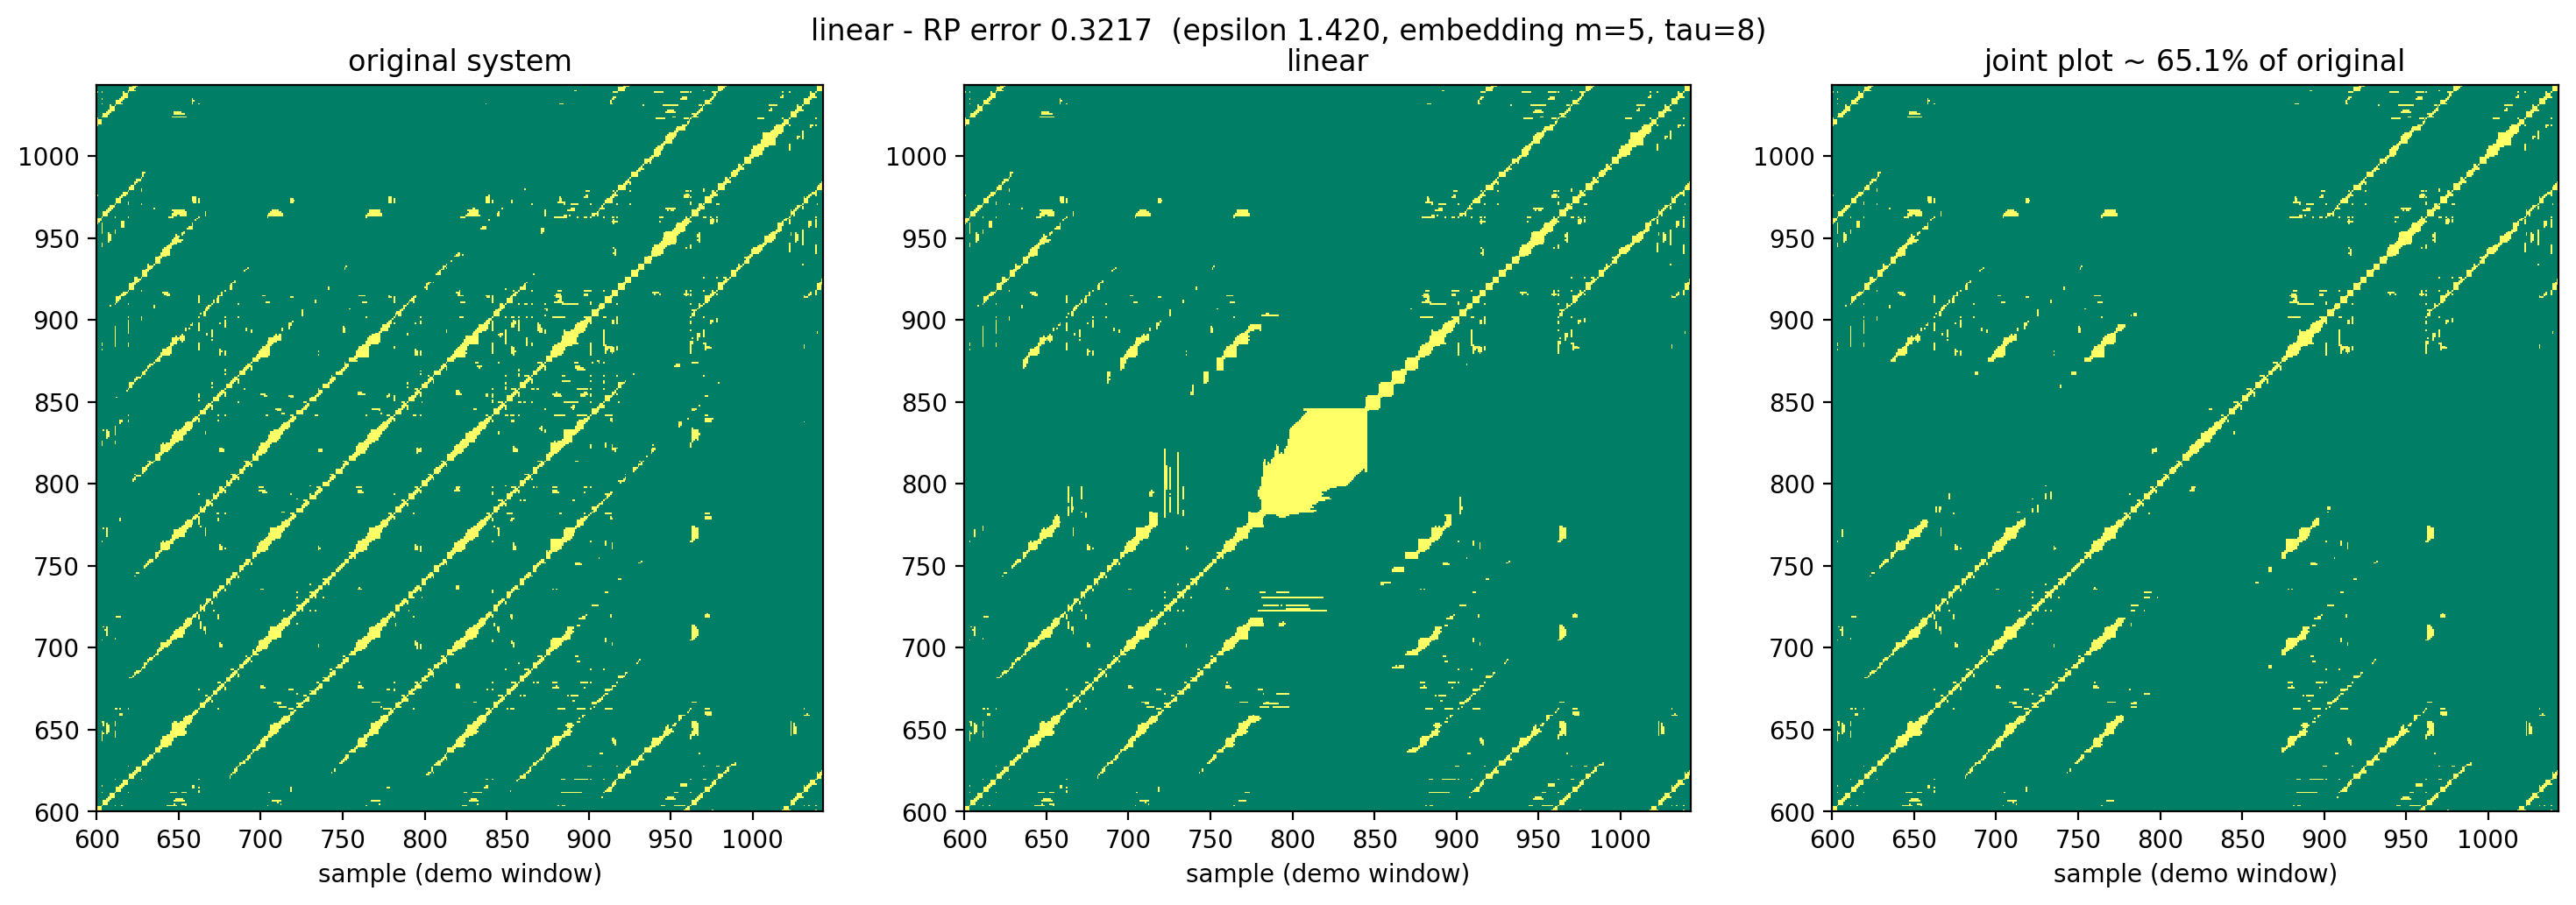

In [13]:
plot_rp_comparison("linear", linear_fill)

In [14]:
from scipy.interpolate import CubicSpline

spline_fill = obs.copy()
spline_fill[~known] = CubicSpline(idx[known], obs[known])(idx[~known])

score("spline", spline_fill)

spline: MAE 1.661, RP error 0.3915


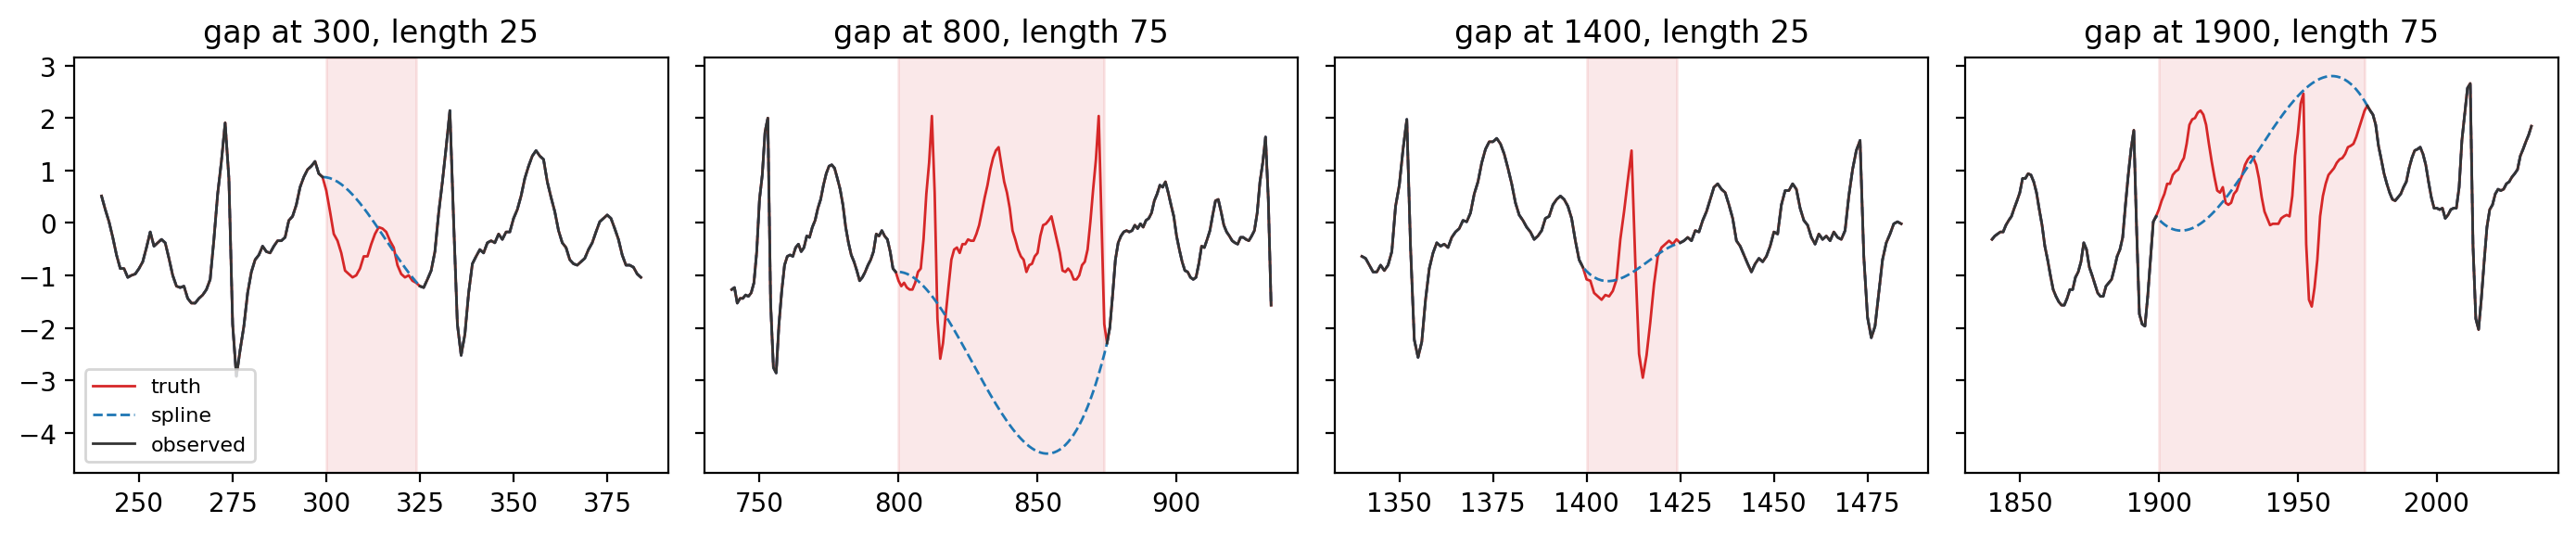

In [15]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], spline_fill[w], color="tab:blue", lw=1, ls="--", label="spline")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

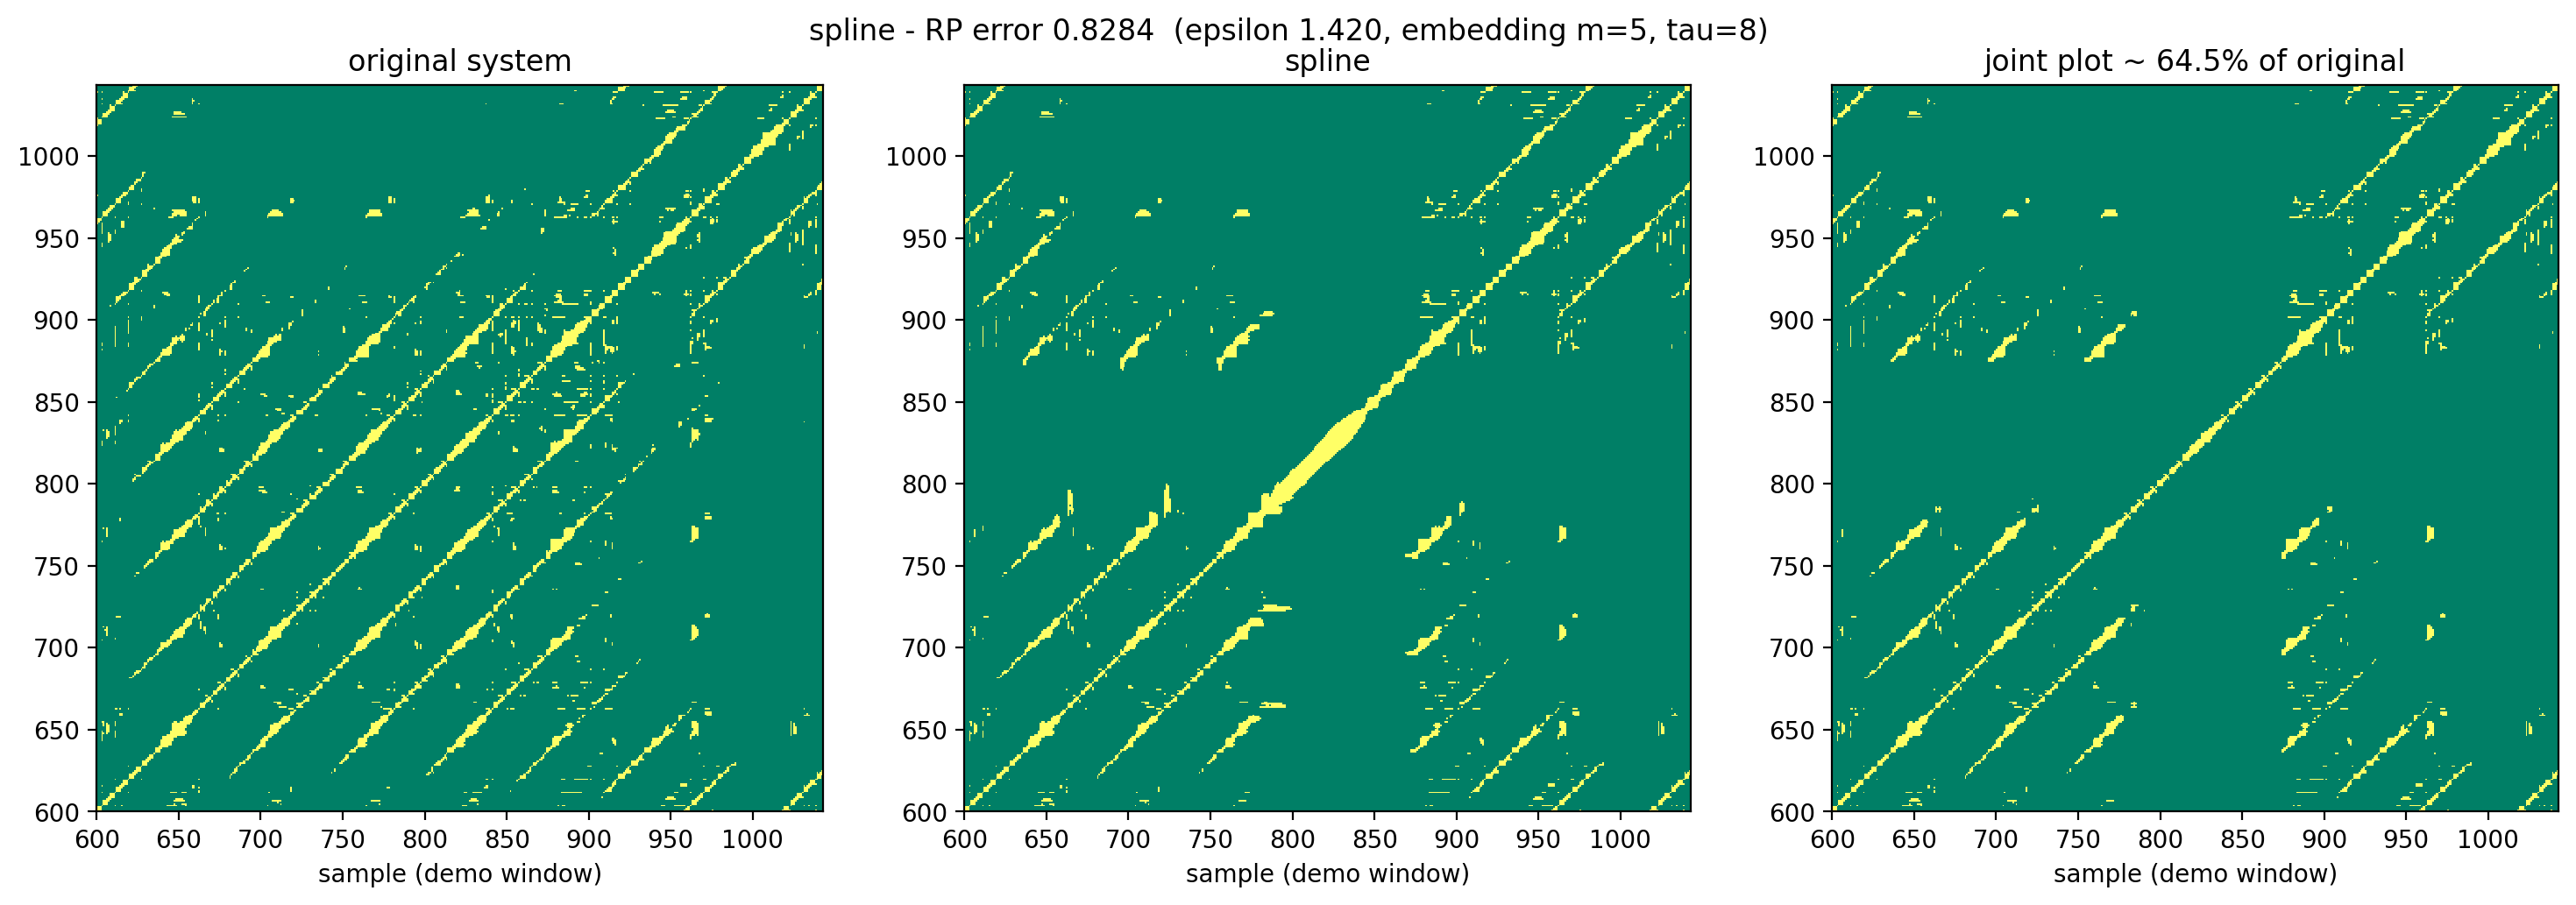

In [16]:
plot_rp_comparison("spline", spline_fill)

In [17]:
# Completion embedding: their ECG setting (M = 50, tau = 1). It is separate from the RP embedding used for scoring.
M_C, TAU_C = 50, 1

def hankel(v, M=M_C, tau=TAU_C):
    # Embedding matrix: 
    # row i = (v_i, v_i+tau, ..., v_i+(M-1)tau)
    n = len(v) - (M - 1) * tau
    return np.column_stack([v[k * tau : k * tau + n] for k in range(M)])

X = hankel(obs)
K = ~np.isnan(X)   # True on known entries
print(f"X: {X.shape[0]} rows x {X.shape[1]} columns, {(~K).sum()} missing entries, "
      f"{(~K).any(axis=1).sum()} rows with at least one missing entry")

X: 2451 rows x 50 columns, 10000 missing entries, 396 rows with at least one missing entry


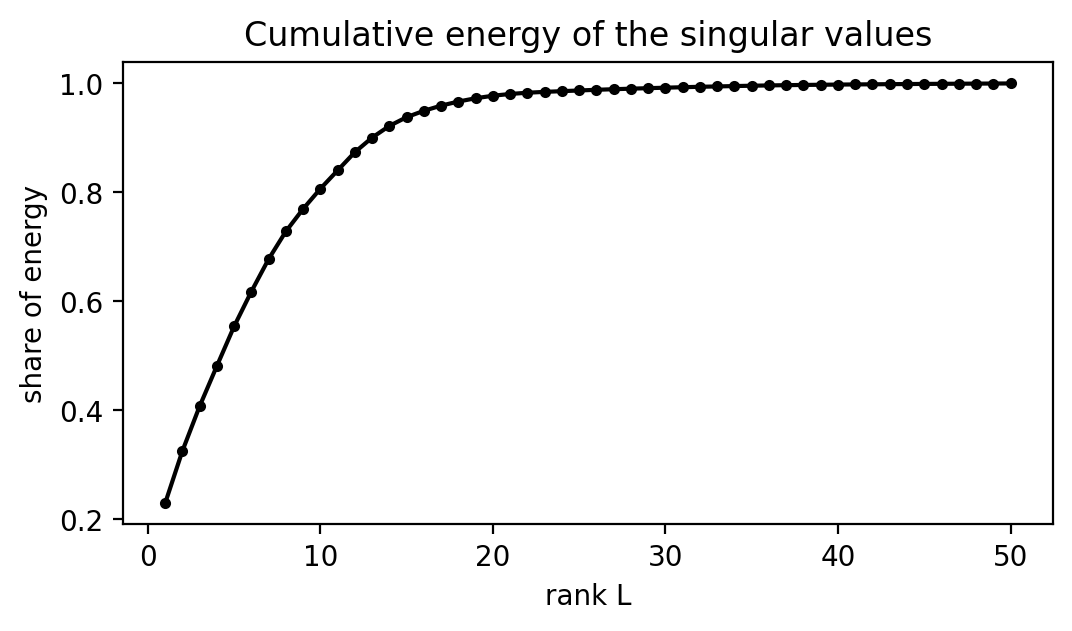

rank needed for 90 / 95 / 99 % of the energy: 13 17 28


In [18]:
# How low-rank is the ECG? 
# Singular values of the rows with no missing entry.
s = np.linalg.svd(X[K.all(axis=1)], compute_uv=False)
energy = np.cumsum(s**2) / np.sum(s**2)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(s) + 1), energy, "k.-")
ax.set_xlabel("rank L")
ax.set_ylabel("share of energy")
ax.set_title("Cumulative energy of the singular values")
plt.show()
print("rank needed for 90 / 95 / 99 % of the energy:",
      *[int(np.searchsorted(energy, q) + 1) for q in (0.90, 0.95, 0.99)])

In [19]:
def fit_low_rank(X, K, L, lam=1.0, n_iter=30, seed=0):
    rng = np.random.default_rng(seed)
    A = np.zeros((X.shape[0], L))
    B = rng.standard_normal((X.shape[1], L))
    I = lam * np.eye(L)
    
    for _ in range(n_iter):
        for i in range(X.shape[0]):
            k = K[i]
            A[i] = np.linalg.solve(B[k].T @ B[k] + I, B[k].T @ X[i, k])
        for j in range(X.shape[1]):
            k = K[:, j]
            B[j] = np.linalg.solve(A[k].T @ A[k] + I, A[k].T @ X[k, j])
    return A, B

In [20]:
L = 8
A, B = fit_low_rank(X, K, L)
X_filled = np.where(K, X, A @ B.T)   # known entries kept, missing ones from the model

print("fit error on the known entries:",
      np.sqrt(np.mean((A @ B.T - X)[K] ** 2)).round(3))

fit error on the known entries: 0.523


In [21]:
# Build the RP directly from X_filled. To score every method with the same RP,
# we turn X_filled back into a series: each missing sample appears once in every row that
# contains it, and we average those copies.
total = np.zeros(n_demo)
count = np.zeros(n_demo)
rows = np.arange(X.shape[0])
for k in range(M_C):
    total[rows + k * TAU_C] += X_filled[:, k]
    count[rows + k * TAU_C] += 1

bousse_fill = obs.copy()
bousse_fill[~known] = total[~known] / count[~known]

score("bousse", bousse_fill)

bousse: MAE 0.824, RP error 0.1421


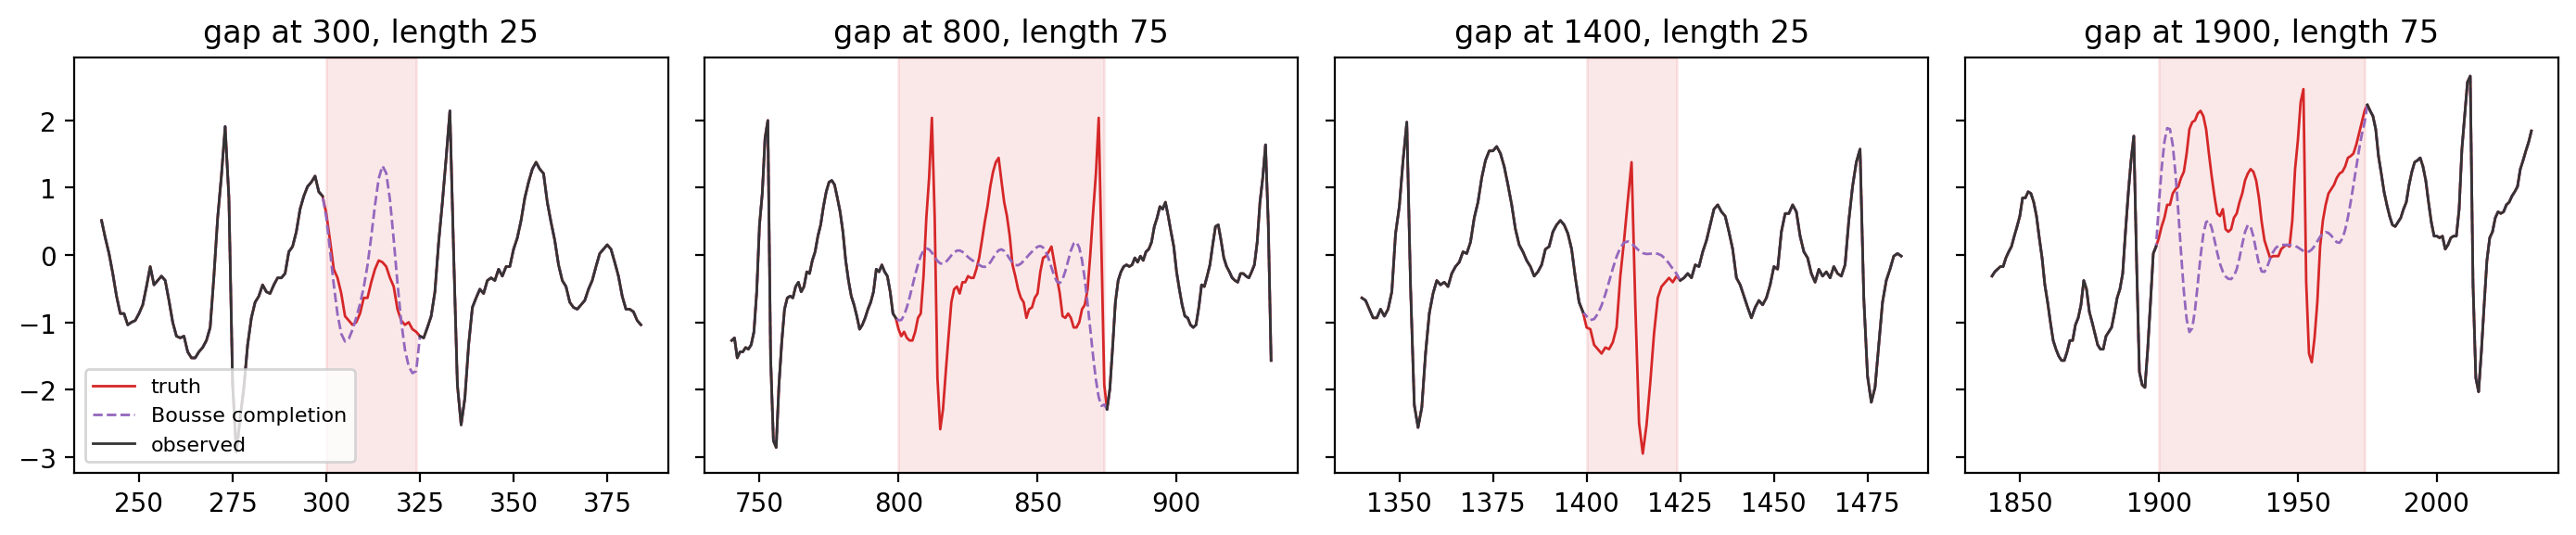

In [22]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], bousse_fill[w], color="tab:purple", lw=1, ls="--", label="Bousse completion")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

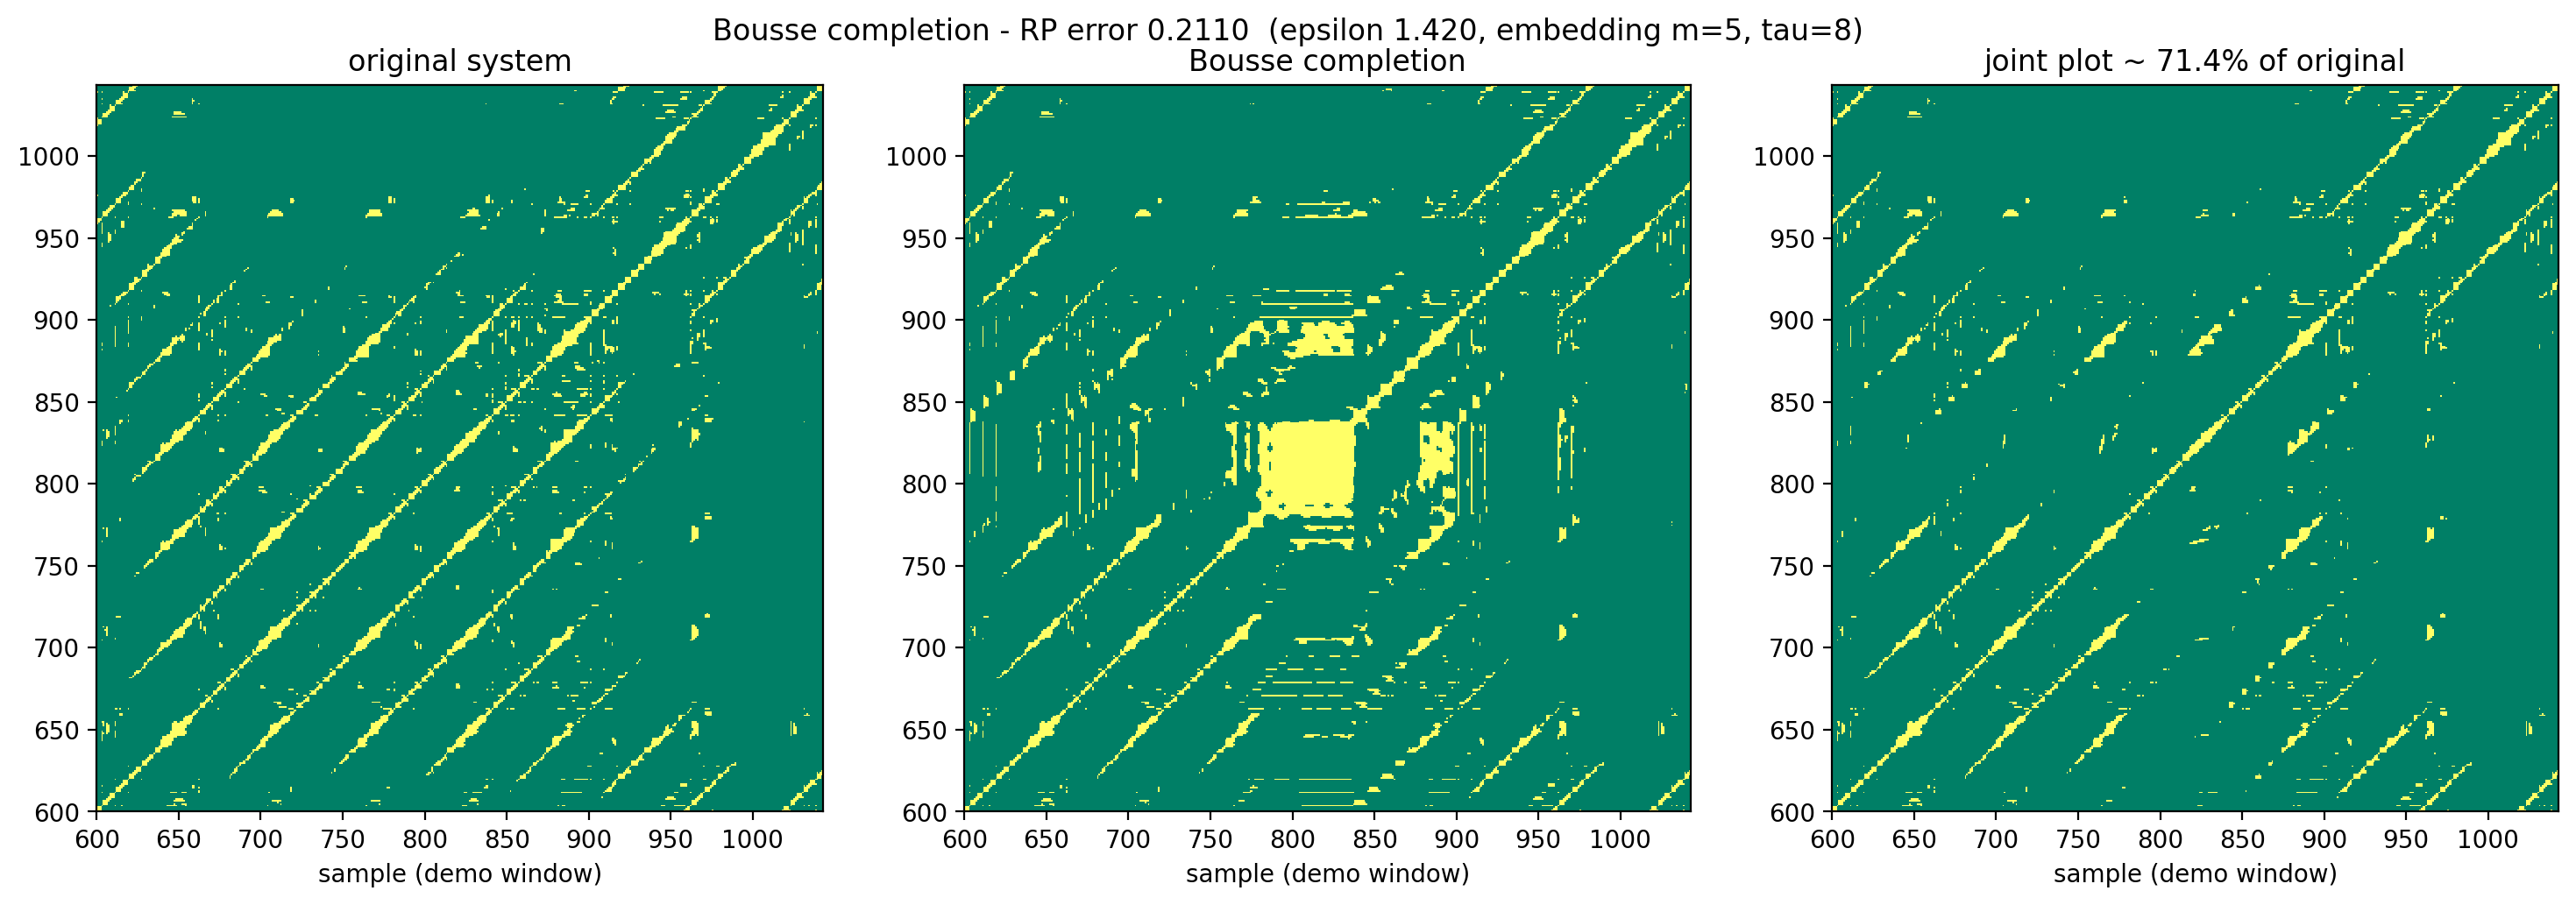

In [23]:
plot_rp_comparison("Bousse completion", bousse_fill)

In [24]:
from numpy.lib.stride_tricks import sliding_window_view

C = 40 # context samples on each side of a gap, used by every recurrence fill below (plain and RQA-filtered)
N_DONORS = 8

library = x[hist] # complete history
query_series = x_obs[demo]   # demo window

In [25]:
def recurrence_fill(query_series, library, channels, C=C, k=N_DONORS):
    # Fill each gap of the target channel with the weighted mean of the k library windows
    # whose observed values best match the window [gap start - C, gap end + C).

    # channels: which columns take part in the matching (the target must be one of them).
    # Returns the filled demo window of the target channel and, per gap, the donors used.
    
    q_all = query_series[:, channels]
    lib = library[:, channels]
    col = channels.index(target)
    filled = query_series[:, target].copy()
    donors = {}
    for start, length in gaps:
        a, b = start - C, start + length + C
        q = q_all[a:b].T                                        # (channels, window), NaN in the gap
        cand = sliding_window_view(lib, b - a, axis=0)          # (library windows, channels, window)
        d = np.nanmean((cand - q) ** 2, axis=(1, 2))            # mean sq. difference on observed entries
        nn = np.argsort(d)[:k]                                  # k nearest library windows
        w = np.exp(-d[nn] / d[nn].min())
        segs = cand[nn, col, C : C + length]                    # what each donor has where the gap is
        filled[start : start + length] = (w[:, None] * segs).sum(axis=0) / w.sum()
        donors[start] = {"starts": nn, "dist": d, "weights": w / w.sum(), "segments": segs}
    return filled, donors

In [26]:
# Matching on the target channel only (context before and after the gap)
rec_own_fill, donors_own = recurrence_fill(query_series, library, channels=[target])
score("recurrence (own channel)", rec_own_fill)

# Matching on both channels: the other channel is observed inside the gap too
rec_both_fill, donors_both = recurrence_fill(query_series, library, channels=[0, 1])
score("recurrence (+ helper)", rec_both_fill)

recurrence (own channel): MAE 0.335, RP error 0.0623
recurrence (+ helper): MAE 0.271, RP error 0.0537


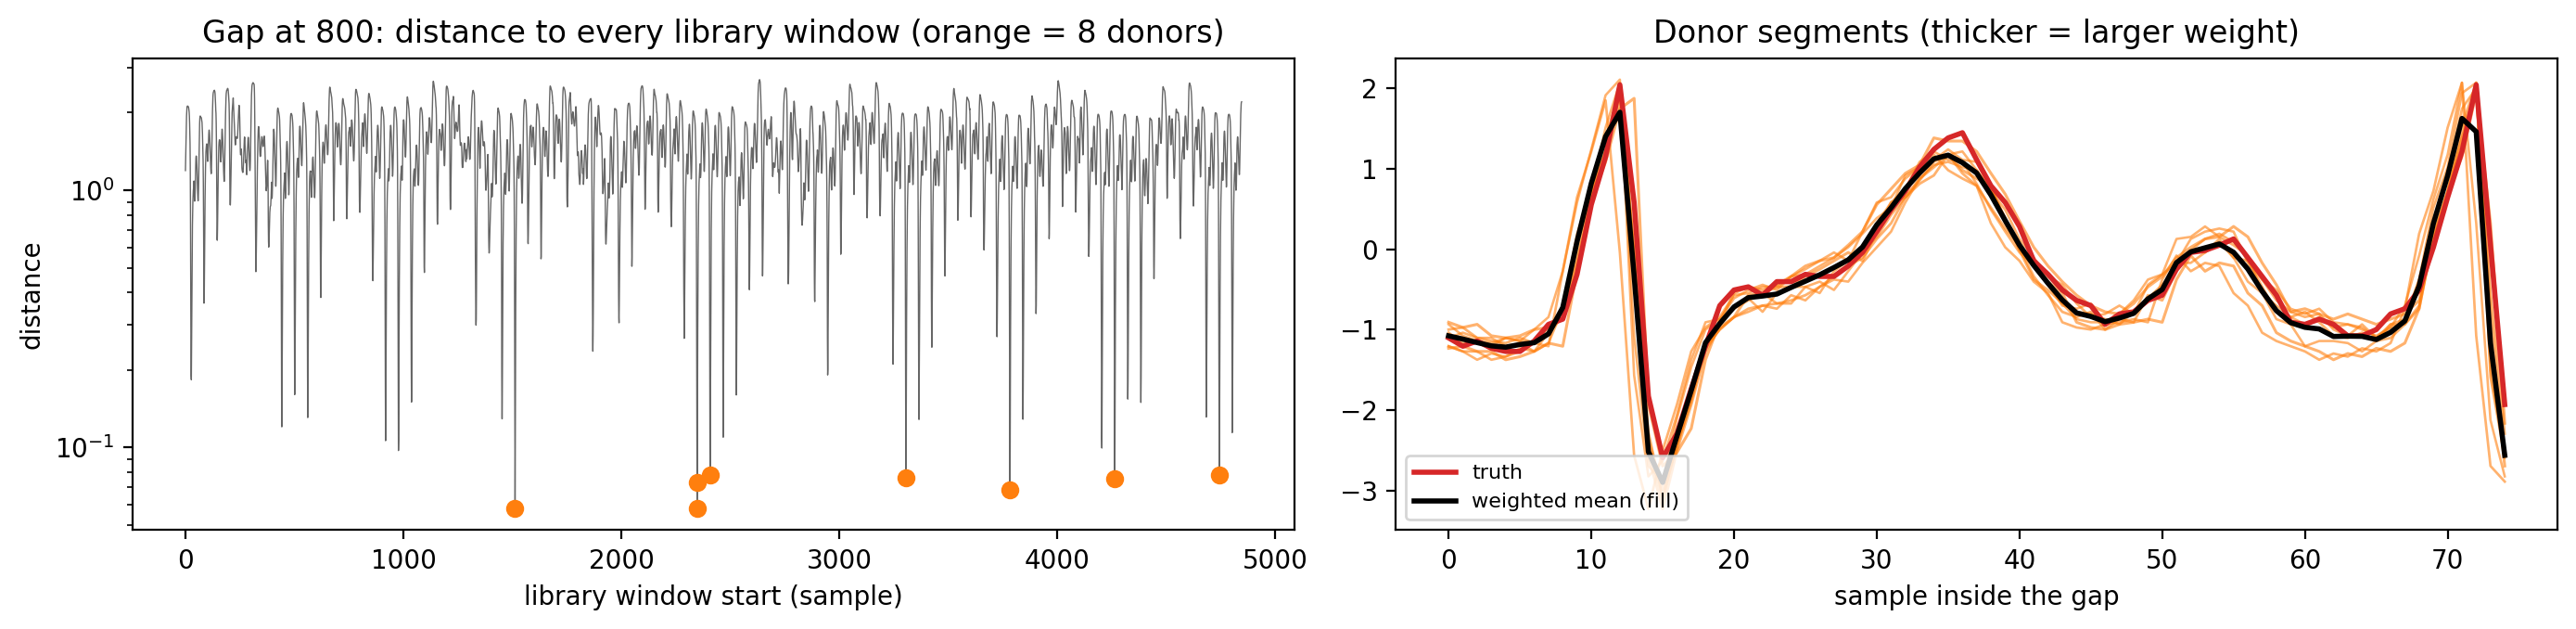

In [27]:
# One gap in detail: the distance to every library window, and the chosen donors
g_start, g_len = gaps[1]
info = donors_own[g_start]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(info["dist"], lw=0.5, color="0.4")
axes[0].plot(info["starts"], info["dist"][info["starts"]], "o", color="tab:orange")
axes[0].set_yscale("log")
axes[0].set_xlabel("library window start (sample)")
axes[0].set_ylabel("distance")
axes[0].set_title(f"Gap at {g_start}: distance to every library window (orange = {N_DONORS} donors)")

for seg, wt in zip(info["segments"], info["weights"]):
    axes[1].plot(seg, color="tab:orange", lw=0.5 + 4 * wt, alpha=0.6)
axes[1].plot(truth[g_start : g_start + g_len], color="tab:red", lw=2, label="truth")
axes[1].plot(rec_own_fill[g_start : g_start + g_len], "k", lw=2, label="weighted mean (fill)")
axes[1].set_xlabel("sample inside the gap")
axes[1].set_title("Donor segments (thicker = larger weight)")
axes[1].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

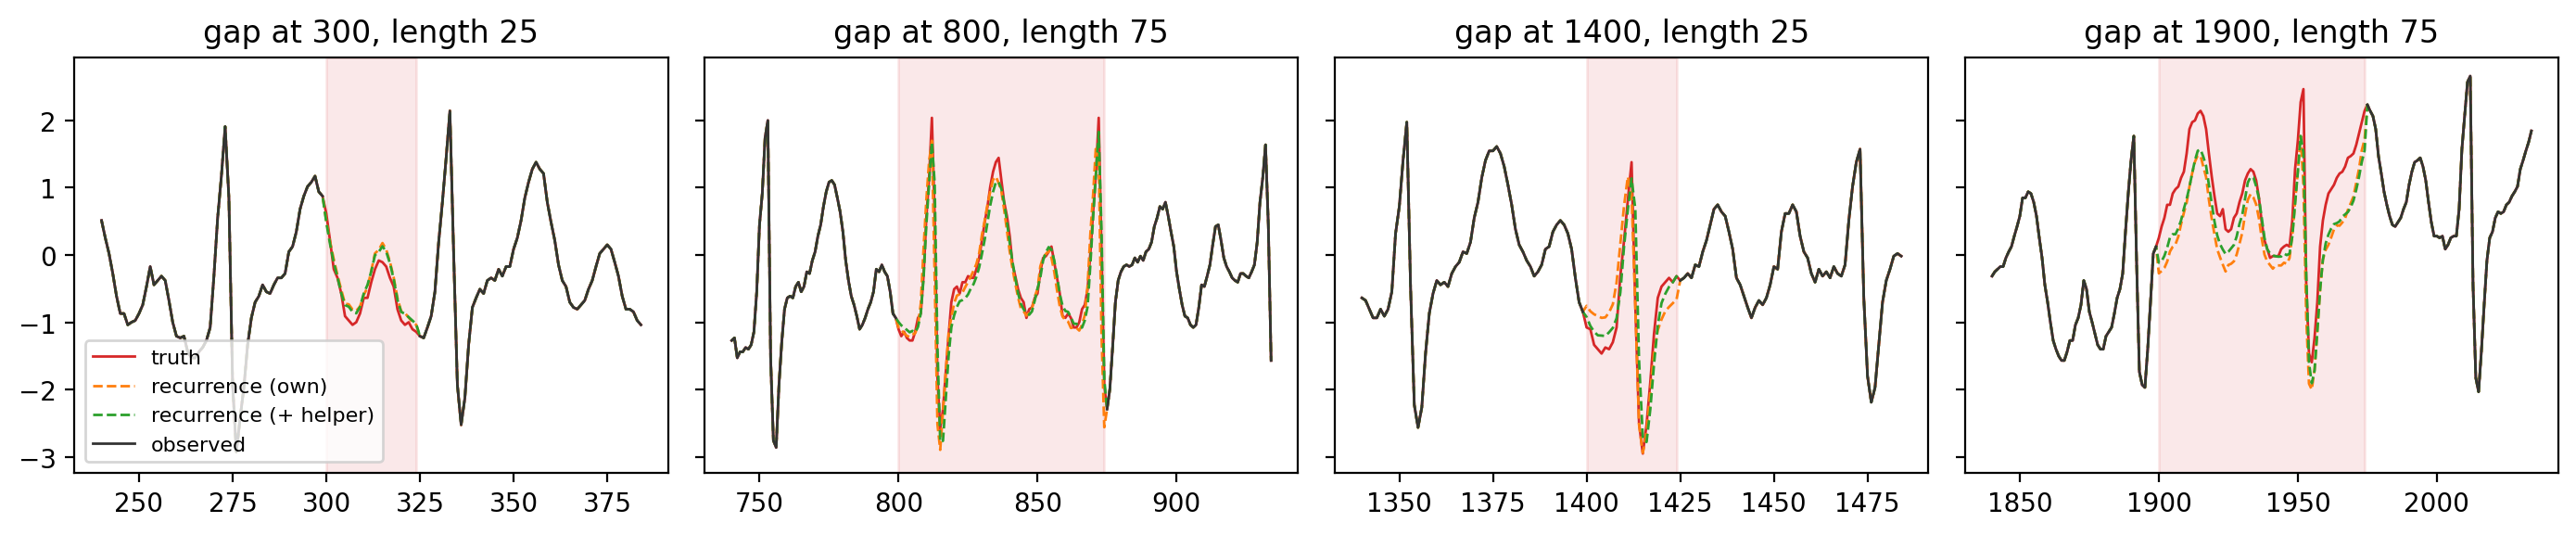

In [28]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], rec_own_fill[w], color="tab:orange", lw=1, ls="--", label="recurrence (own)")
    ax.plot(idx[w], rec_both_fill[w], color="tab:green", lw=1, ls="--", label="recurrence (+ helper)")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

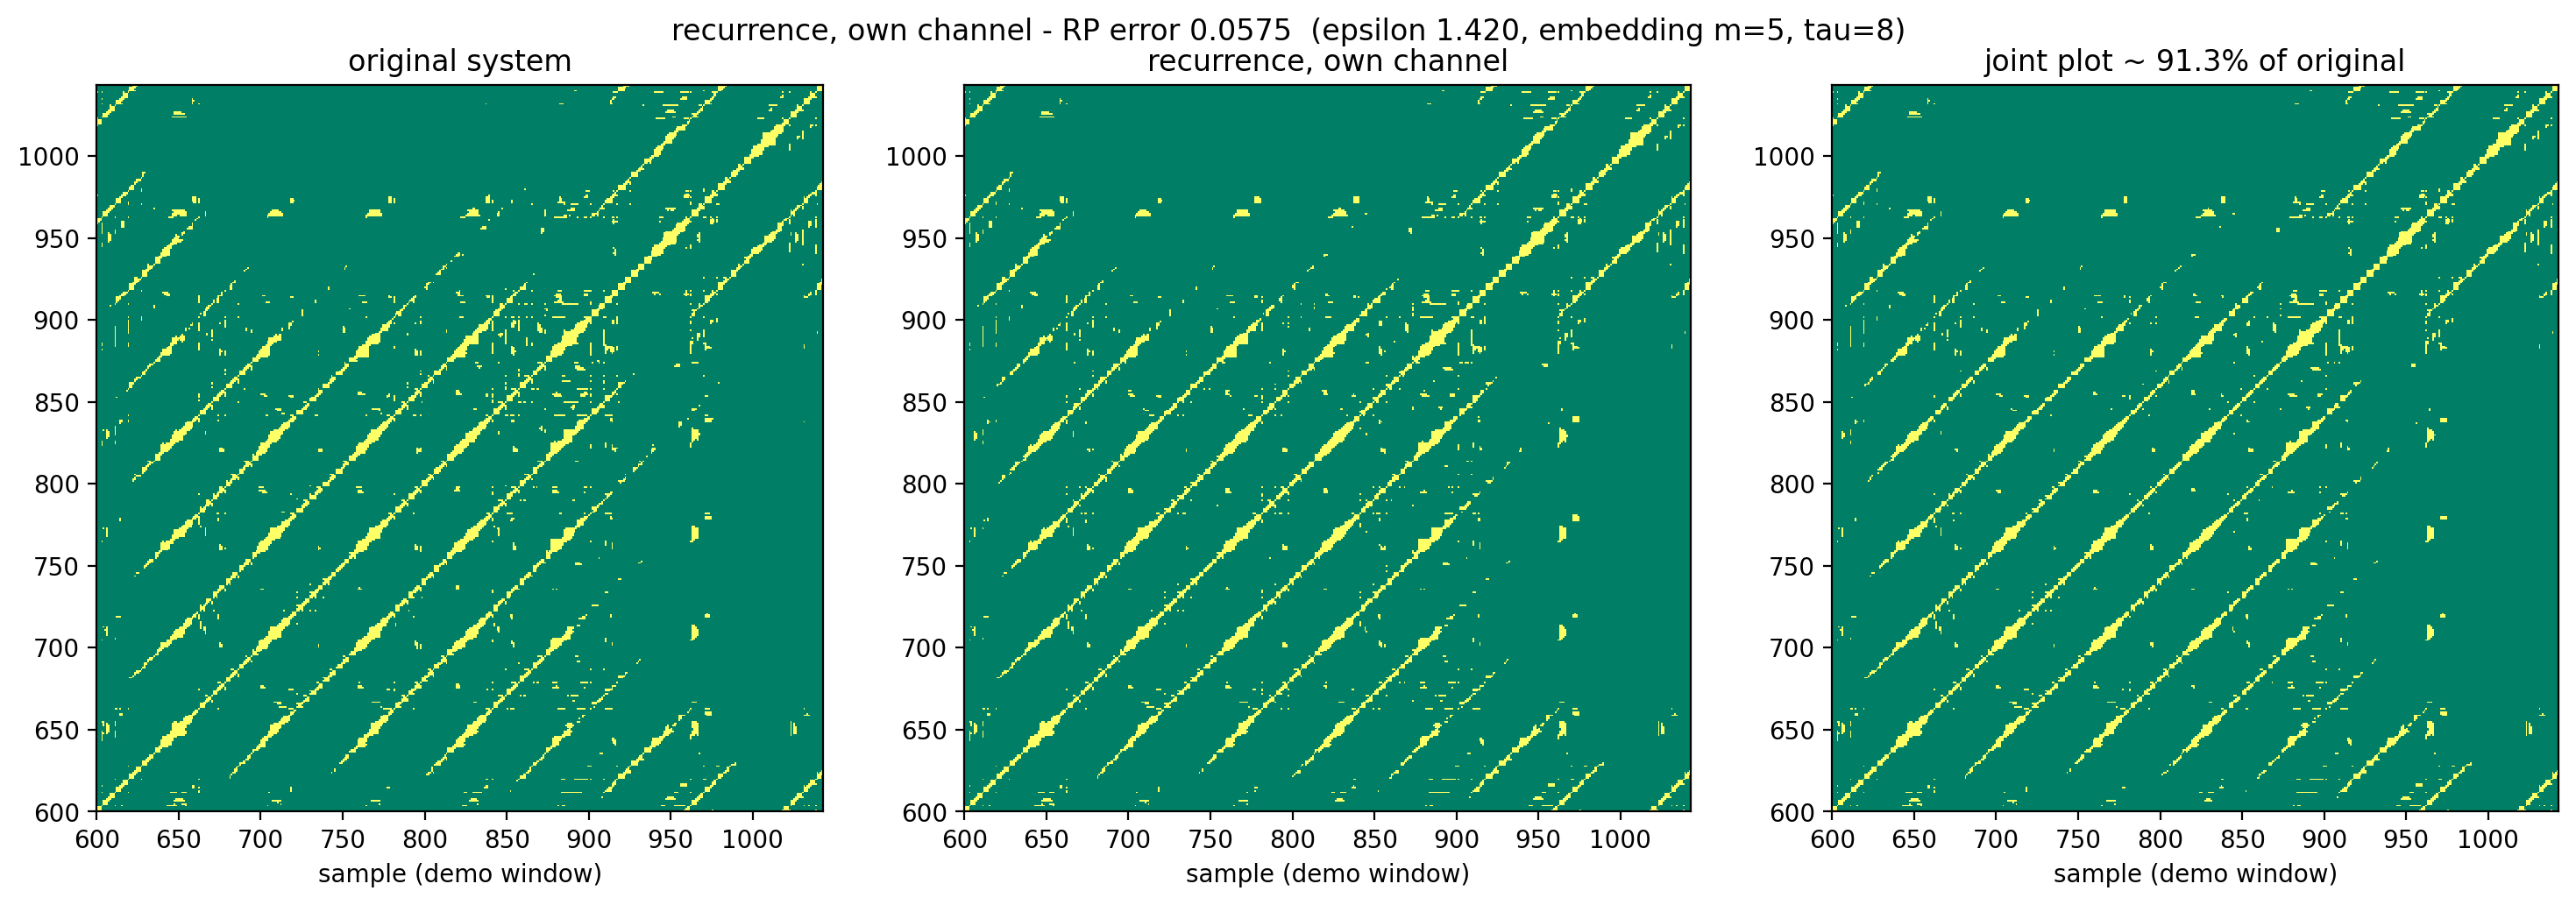

In [29]:
plot_rp_comparison("recurrence, own channel", rec_own_fill)

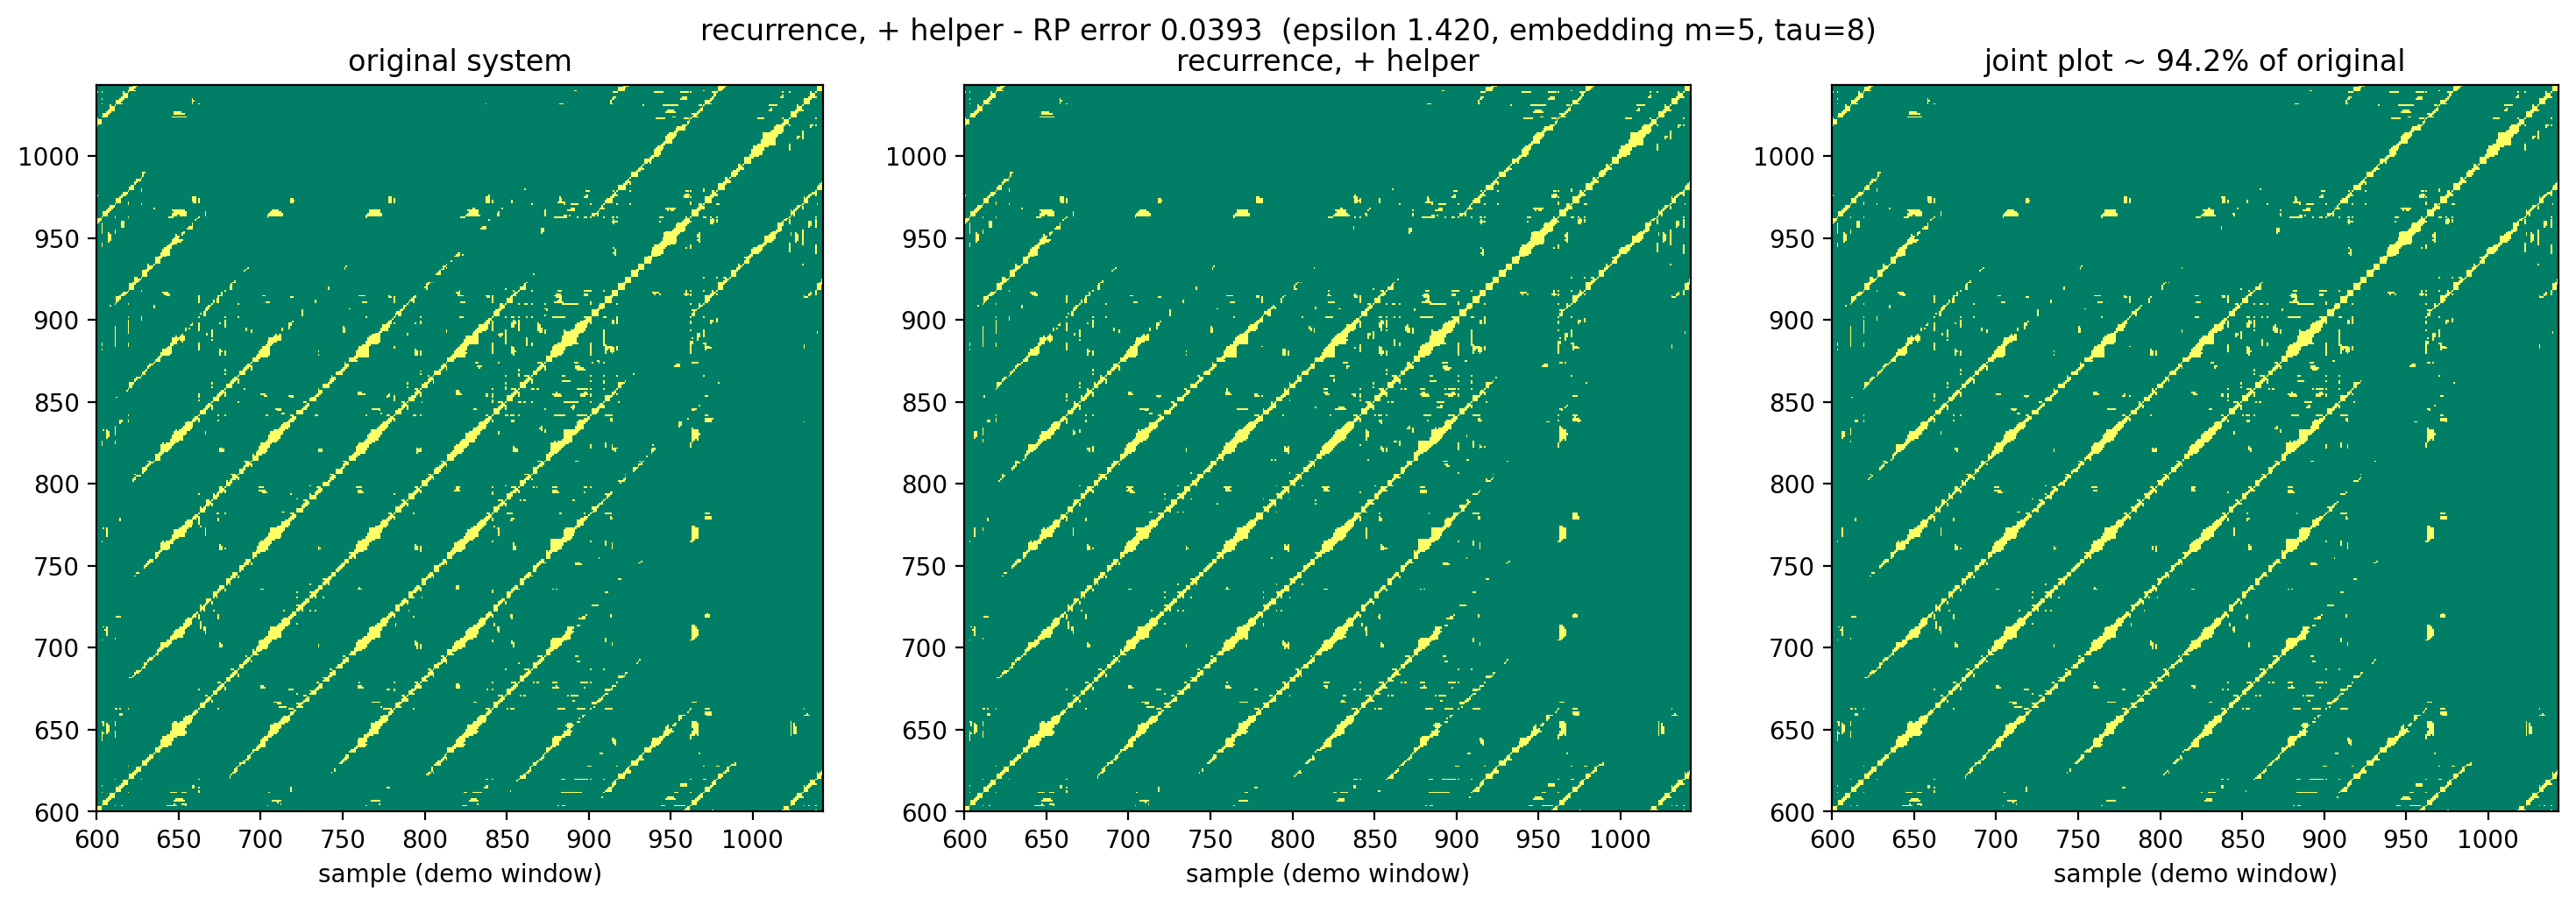

In [30]:
plot_rp_comparison("recurrence, + helper", rec_both_fill)

## Recurrence fill with an RQA filter on the chunks beside the gap

The neighbour search above stays as it is: library windows are ranked by the mean squared
difference on the observed entries of the window around the gap, and the fill is the weighted
mean of the best 8, with weights $\exp(-d/d_{\min})$. This section adds one filter between the
ranking and the choice of the 8 donors:

1. Take the 32 library windows with the smallest distance (`RQA_POOL`).
2. For the query and for each of those candidates, compute DET, LAM and ENTR on the chunk
   immediately before the gap and on the chunk immediately after it.
3. Keep the half of the shortlist whose DET/LAM/ENTR values differ least from the query's
   (mean absolute difference over the 3 measures and the 2 chunks).
4. From the kept windows, take the 8 with the smallest original distance, with the same
   weights as before.

The RQA chunks are the two matching contexts themselves: the $C=40$ samples immediately
before the gap and the $C$ samples immediately after it. They use their own embedding,
$m=5$, $\tau=2$, so each chunk gives $40-(5-1)\cdot2=32$ states and a $32\times32$ RP; the
notebook embedding ($m=5$, $\tau=8$) is still used for scoring the reconstructions, but not here.

Because $C$ is the notebook-wide context, the plain recurrence fills above also use $C=40$;
any gain from the larger context shows in their scores, and the filtered arms below differ
from them only by the RQA filter.

The RQA values are computed on the target channel only, so the same filter is applied to the
own-channel and the +helper variants; in the +helper variant the helper channel still enters
through the distance. Each chunk RP has a recurrence rate of 10 % over the pairs off the main
diagonal, and DET/LAM/ENTR come from `recplay.rqa.rqa`.

In [31]:
import sys

sys.path.insert(0, "../../src")
from recplay.rqa import rqa as _rqa_measures

RQA_M, RQA_TAU = 5, 2   # embedding of the chunk RPs: a chunk of C samples gives C - (m-1)*tau states
RQA_RR = 0.10     # recurrence rate of each chunk RP, off the main diagonal
RQA_POOL = 32     # shortlist from the distance ranking that the filter is applied to
RQA_KEEP = 0.5    # share of the shortlist kept after the filter (the half with smallest RQA difference)
RQA_MEASURES = ("DET", "LAM", "ENTR")


def chunk_rqa(v):
    # DET, LAM, ENTR of one C-sample chunk of the target channel (RQA_M, RQA_TAU embedding).
    v = np.asarray(v, float)
    e = embed(v, RQA_M, RQA_TAU)
    d = cdist(e, e)
    n = len(d)
    allowed = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :]) >= 1
    R = d <= np.quantile(d[allowed], RQA_RR)
    R[~allowed] = False
    q = _rqa_measures(R)
    return np.array([q[k] for k in RQA_MEASURES], float)

In [32]:
def recurrence_fill_rqa(query_series, library, channels, C=C, k=N_DONORS,
                        pool=RQA_POOL, keep=RQA_KEEP):
    # recurrence_fill plus the RQA filter: the shortlist of `pool` nearest library windows is
    # reduced to the `keep` share with the smallest DET/LAM/ENTR difference on the two chunks
    # beside the gap, then the k nearest of the kept windows are used, as in recurrence_fill.
    # Returns the filled target channel and, per gap, the donors and the shortlist table.
    q_all = query_series[:, channels]
    lib = library[:, channels]
    col = channels.index(target)
    filled = query_series[:, target].copy()
    donors = {}
    for start, length in gaps:
        a, b = start - C, start + length + C
        q = q_all[a:b].T                                        # (channels, window), NaN in the gap
        cand = sliding_window_view(lib, b - a, axis=0)          # (library windows, channels, window)
        d = np.nanmean((cand - q) ** 2, axis=(1, 2))            # same distance as recurrence_fill
        shortlist = np.argsort(d)[:pool]

        q_feat = [chunk_rqa(query_series[start - C : start, target]),
                  chunk_rqa(query_series[start + length : start + length + C, target])]
        rows = []
        for s in shortlist:
            mid = s + C                                         # where this candidate's gap segment starts
            lo, hi = mid - C, mid + length + C
            if lo < 0 or hi > len(library):
                diff = np.full((2, len(RQA_MEASURES)), np.inf)  # chunks not fully inside the history
            else:
                c_feat = [chunk_rqa(library[lo:mid, target]),
                          chunk_rqa(library[mid + length : hi, target])]
                diff = np.abs(np.array(c_feat) - np.array(q_feat))
            rows.append({"start": int(s), "dist": d[s],
                         **{f"d{m}_{side}": diff[i, j] for i, side in enumerate(("left", "right"))
                            for j, m in enumerate(RQA_MEASURES)},
                         "rqa_diff": float(diff.mean())})
        table = pd.DataFrame(rows)
        finite = table[np.isfinite(table["rqa_diff"])]
        kept = finite.loc[finite["rqa_diff"] <= finite["rqa_diff"].quantile(keep), "start"].to_numpy()
        if len(kept) < k:
            raise ValueError(f"gap at {start}: RQA filter kept {len(kept)} of {pool} candidates, need {k}")
        nn = kept[np.argsort(d[kept])[:k]]                      # nearest kept windows, as before
        d_min = d[nn].min()
        w = np.exp(-d[nn] / d_min) if d_min > 0 else np.ones_like(d[nn])
        segs = cand[nn, col, C : C + length]
        filled[start : start + length] = (w[:, None] * segs).sum(axis=0) / w.sum()
        donors[start] = {"starts": nn, "dist": d, "weights": w / w.sum(), "segments": segs,
                         "rqa_table": table}
    return filled, donors

In [33]:
# Same two variants as above, with the RQA filter on the chunks beside the gap
rec_rqa_own_fill, donors_rqa_own = recurrence_fill_rqa(query_series, library, channels=[target])
score("recurrence (own channel) + RQA filter", rec_rqa_own_fill)

rec_rqa_both_fill, donors_rqa_both = recurrence_fill_rqa(query_series, library, channels=[0, 1])
score("recurrence (+ helper) + RQA filter", rec_rqa_both_fill)

recurrence (own channel) + RQA filter: MAE 0.319, RP error 0.0606
recurrence (+ helper) + RQA filter: MAE 0.244, RP error 0.0515


In [34]:
# What the filter changed, per gap: donors chosen with and without it, and the mean RQA
# difference (over DET, LAM, ENTR and the two chunks) of the chosen donors.
rows = []
for variant, plain, filtered in [("own channel", donors_own, donors_rqa_own),
                                 ("+ helper", donors_both, donors_rqa_both)]:
    for start, length in gaps:
        chosen = filtered[start]["starts"]
        tab = filtered[start]["rqa_table"].set_index("start")
        rows.append({"variant": variant, "gap start": start, "gap length": length,
                     "donors without filter": ", ".join(map(str, plain[start]["starts"])),
                     "donors with filter": ", ".join(map(str, chosen)),
                     "donors kept": int(len(set(chosen) & set(plain[start]["starts"]))),
                     "mean RQA difference of chosen": tab.loc[chosen, "rqa_diff"].mean()})
rqa_filter_summary = pd.DataFrame(rows)
rqa_filter_summary.round(3)

,variant,gap start,gap length,donors without filter,donors with filter,donors kept,mean RQA difference of chosen
0,own channel,300,25,"4302, 4841, 2386, 4781, 3821, 540, 5, 3403","4302, 4841, 2386, 4781, 5, 3344, 4242, 3881",5,0.065
1,own channel,800,75,"1512, 2347, 3782, 2348, 4263, 3305, 2407, 4743","1512, 2347, 2348, 4263, 3305, 1513, 977, 3306",5,0.063
2,own channel,1400,25,"621, 86, 620, 2587, 2586, 85, 87, 622","621, 2587, 87, 622, 1096, 3006, 4683, 2886",4,0.079
3,own channel,1900,75,"1593, 1653, 1652, 2069, 4464, 2009, 3505, 3504","1653, 1652, 2069, 4464, 3505, 3923, 2070, 1057",5,0.093
4,+ helper,300,25,"4781, 4841, 4302, 4242, 3821, 5, 4722, 3761","4781, 4302, 4242, 5, 4722, 957, 3344, 2386",5,0.062
5,+ helper,800,75,"4263, 3782, 4262, 3781, 3305, 3304, 4203, 4742","4263, 3781, 3305, 3304, 4203, 2347, 4204, 4323",5,0.072
6,+ helper,1400,25,"620, 621, 4442, 4443, 619, 2586, 3006, 3483","621, 619, 3006, 3483, 3005, 3482, 3484, 2587",4,0.071
7,+ helper,1900,75,"1652, 1653, 3028, 4464, 3027, 3504, 3505, 641","1652, 1653, 4464, 641, 1651, 2069, 642, 4465",4,0.080


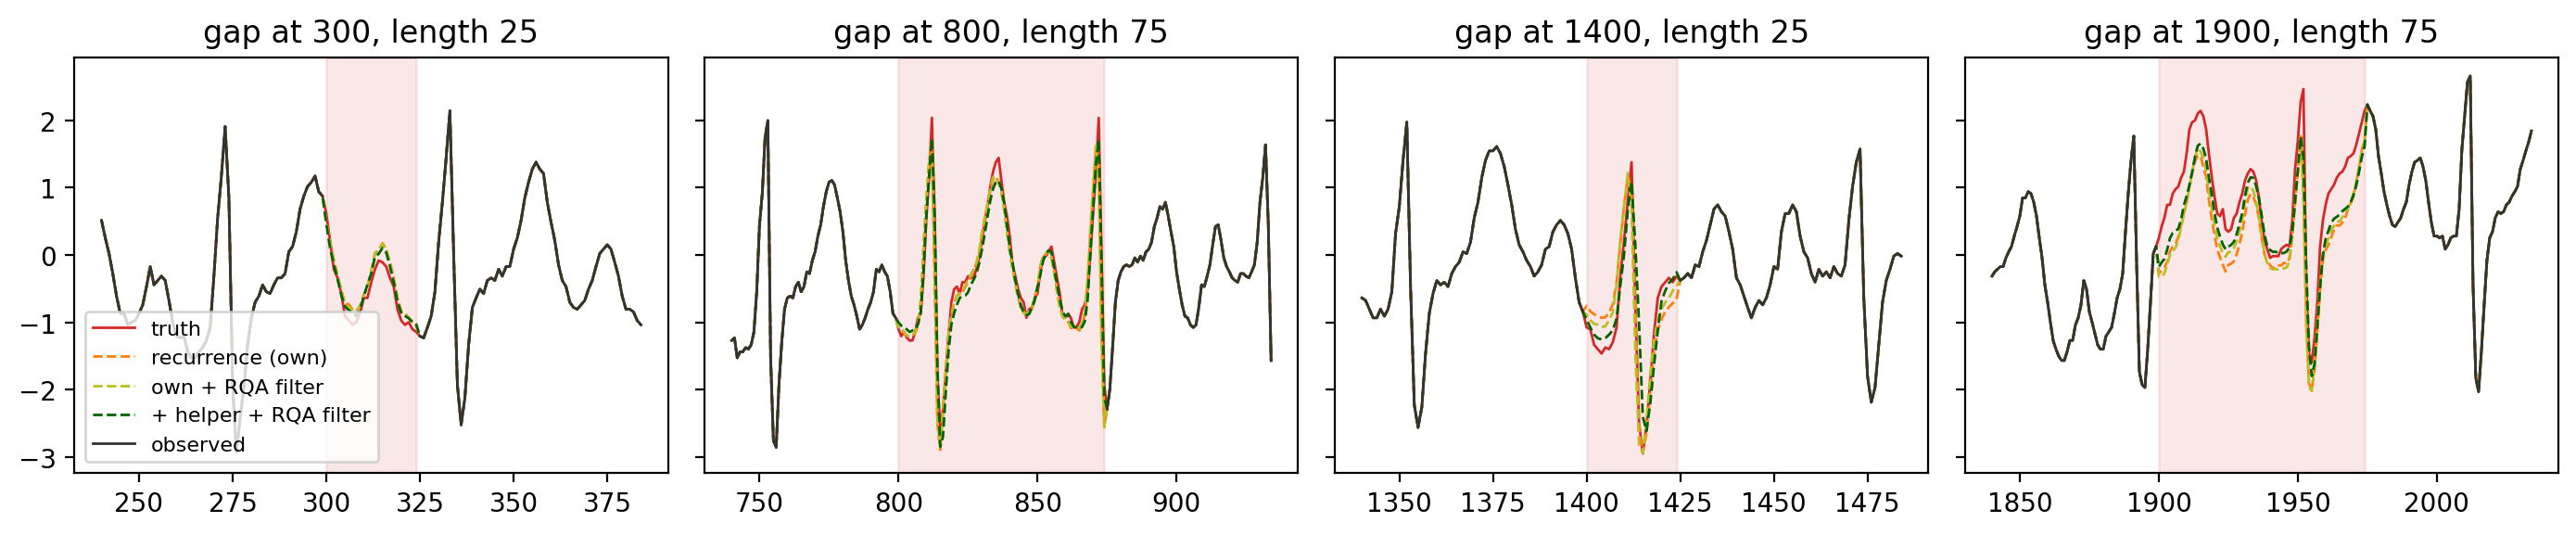

In [35]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], rec_own_fill[w], color="tab:orange", lw=1, ls="--", label="recurrence (own)")
    ax.plot(idx[w], rec_rqa_own_fill[w], color="tab:olive", lw=1, ls="--", label="own + RQA filter")
    ax.plot(idx[w], rec_rqa_both_fill[w], color="darkgreen", lw=1, ls="--", label="+ helper + RQA filter")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

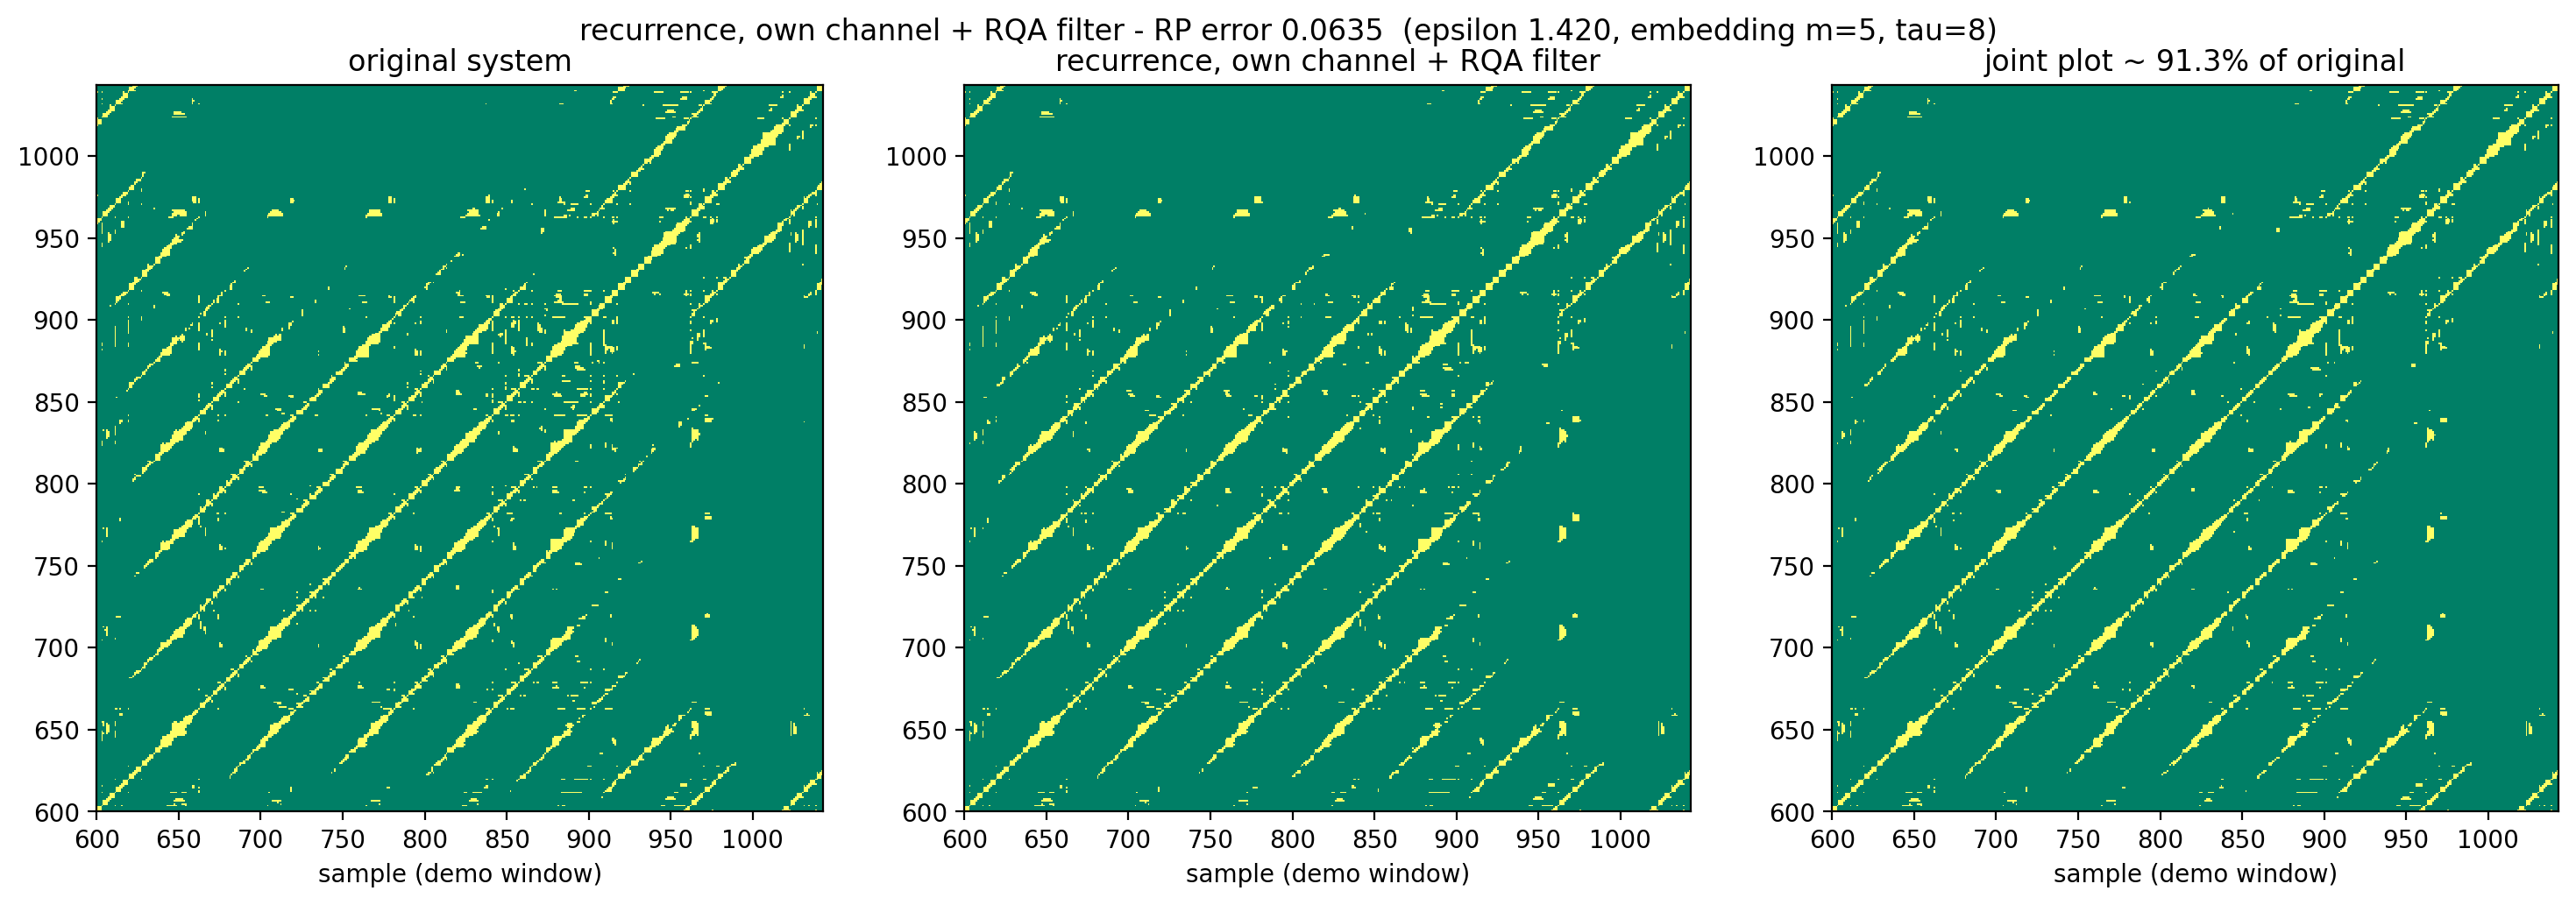

In [36]:
plot_rp_comparison("recurrence, own channel + RQA filter", rec_rqa_own_fill)

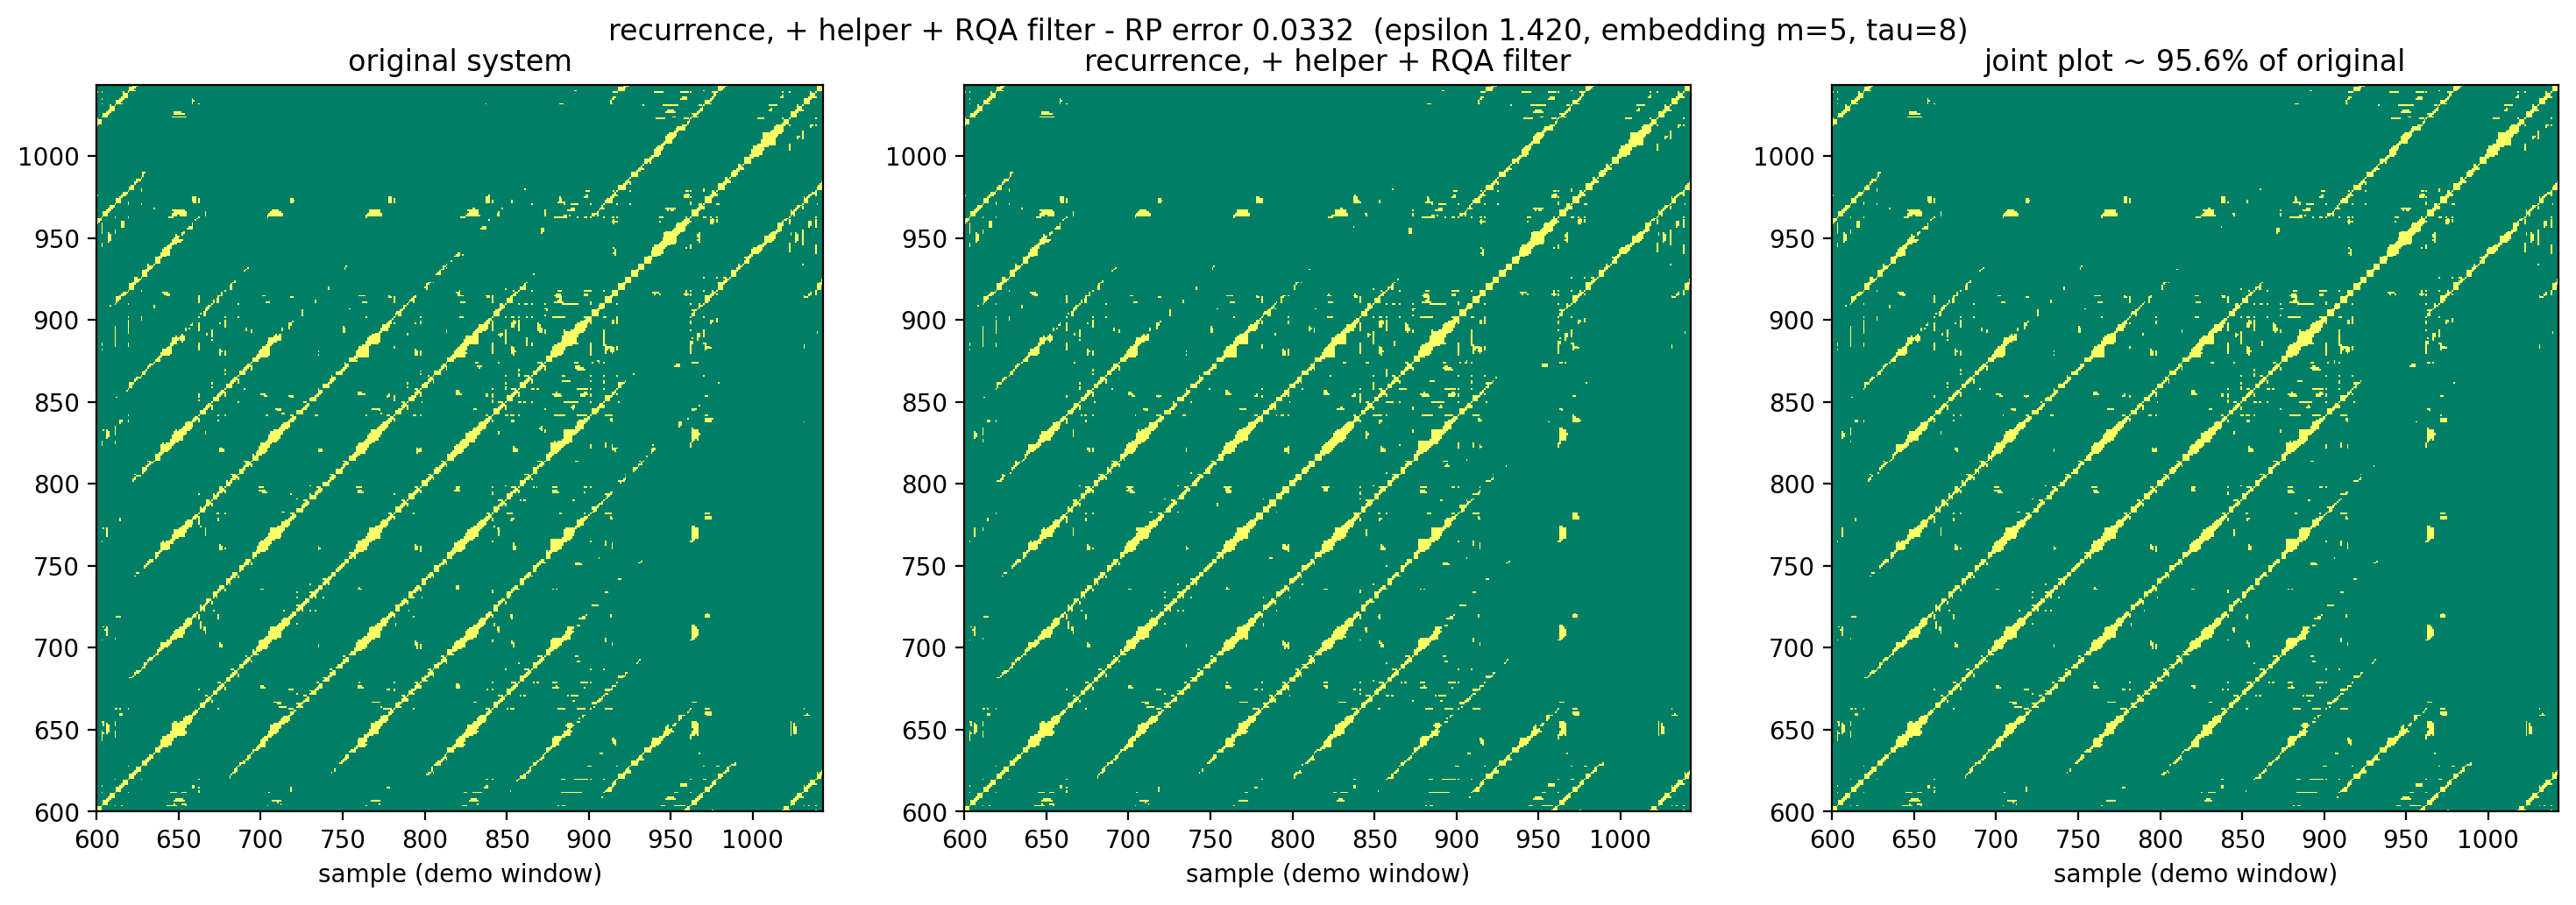

In [37]:
plot_rp_comparison("recurrence, + helper + RQA filter", rec_rqa_both_fill)

## Multiscale version: context length adapts to the available neighbours

The method above fixes $C=40$. This version runs the same distance + RQA-filter calculation at
several context lengths, `MS_SCALES = (80, 40, 25)`, and combines the results across scales.
At each scale the query chunks and the candidate chunks have that scale's length, so DET, LAM
and ENTR are only ever compared between chunks of equal length; with $m=5$, $\tau=2$ the chunks
give 72, 32 and 17 states at the three scales, so the chunk RPs are $72\times72$, $32\times32$ and $17\times17$. Raw distances
and RQA differences are not comparable across scales, so across scales the candidates are
combined by their ranks within each scale's shortlist:

$$S(s,C)=\frac{\mathrm{rank}(d_C(s))}{n}+\frac{\mathrm{rank}(D_{\mathrm{RQA}}(s,C))}{n}.$$

Two reconstructions are built from the same per-scale results. **Multiscale average:** at each
scale, the donors chosen by the RQA filter contribute their usual weights; a donor segment
that is chosen at several scales has its weights added together, so it is counted once, and the
fill is the weighted mean over all distinct donor segments. **Multiscale best-one:** the single
shortlist candidate with the smallest $S(s,C)$ over all scales is copied into the gap
unchanged. Both are run on the target channel only, so they compare directly with
`recurrence (own channel)` and `recurrence (own channel) + RQA filter`.

In [39]:
MS_SCALES = (80, 40, 25)   # context lengths tried per gap, largest first


def multiscale_fills(query_series, library, channels=[target], scales=MS_SCALES, k=N_DONORS):
    # Run recurrence_fill_rqa once per scale, then combine over scales per gap.
    # Returns (average fill, best-one fill, diagnostics per gap start).
    per_scale = {Cs: recurrence_fill_rqa(query_series, library, channels, C=Cs, k=k)[1]
                 for Cs in scales}
    avg_fill = query_series[:, target].copy()
    best_fill = query_series[:, target].copy()
    diag = {}
    for start, length in gaps:
        agg = {}          # donor segment start -> [total weight, segment]
        scale_donors, n_pass = {}, {}
        best_row = None
        for Cs in scales:
            info = per_scale[Cs][start]
            table = info["rqa_table"]
            finite = table[np.isfinite(table["rqa_diff"])]
            n_pass[Cs] = int((finite["rqa_diff"] <= finite["rqa_diff"].quantile(RQA_KEEP)).sum())

            # rank combination over this scale's shortlist, for the best-one choice
            score = (table["dist"].rank() + table["rqa_diff"].rank()) / len(table)
            j = score.idxmin()
            row = {"C": Cs, "seg_start": int(table.loc[j, "start"]) + Cs,
                   "score": float(score.loc[j]), "dist": float(table.loc[j, "dist"]),
                   "rqa_diff": float(table.loc[j, "rqa_diff"])}
            if best_row is None or row["score"] < best_row["score"]:
                best_row = row

            # donors chosen at this scale, identified by segment start so the same
            # segment found at several scales is aggregated, not counted twice
            seg_starts = [int(s) + Cs for s in info["starts"]]
            scale_donors[Cs] = seg_starts
            for seg_start, wt, seg in zip(seg_starts, info["weights"], info["segments"]):
                if seg_start in agg:
                    agg[seg_start][0] += wt
                else:
                    agg[seg_start] = [wt, seg]
        seg_starts = sorted(agg)
        weights = np.array([agg[s][0] for s in seg_starts])
        weights /= weights.sum()
        segs = np.array([agg[s][1] for s in seg_starts])
        avg_fill[start : start + length] = (weights[:, None] * segs).sum(axis=0)
        b = best_row["seg_start"]
        best_fill[start : start + length] = library[b : b + length, target]
        diag[start] = {"scale_donors": scale_donors, "n_pass": n_pass,
                       "avg_donors": seg_starts, "avg_weights": weights, "best": best_row}
    return avg_fill, best_fill, diag

In [40]:
ms_avg_fill, ms_best_fill, ms_diag = multiscale_fills(query_series, library, channels=[target])
score("multiscale RQA average (own channel)", ms_avg_fill)
score("multiscale RQA best-one (own channel)", ms_best_fill)

multiscale RQA average (own channel): MAE 0.326, RP error 0.0640
multiscale RQA best-one (own channel): MAE 0.363, RP error 0.0639


In [41]:
# Per gap: what each scale contributed, the aggregated donors of the average, and the
# single donor of the best-one arm. If the largest scale always wins the best-one choice,
# the multiscale part is adding nothing over fixing that scale.
rows = []
for start, length in gaps:
    dg = ms_diag[start]
    rows.append({"gap start": start, "gap length": length,
                 "candidates passing per scale": ", ".join(
                     f"C={Cs}: {dg['n_pass'][Cs]}" for Cs in MS_SCALES),
                 "donors per scale (segment starts)": "; ".join(
                     f"C={Cs}: {dg['scale_donors'][Cs]}" for Cs in MS_SCALES),
                 "average donors": dg["avg_donors"],
                 "average weights": np.round(dg["avg_weights"], 3).tolist(),
                 "best-one scale": dg["best"]["C"],
                 "best-one donor (segment start)": dg["best"]["seg_start"],
                 "best-one score": round(dg["best"]["score"], 3),
                 "best-one RQA difference": round(dg["best"]["rqa_diff"], 3)})
ms_summary = pd.DataFrame(rows)
ms_summary

,gap start,gap length,candidates passing per scale,donors per scale (segment starts),average donors,average weights,best-one scale,best-one donor (segment start),best-one score,best-one RQA difference
0,300,25,"C=80: 16, C=40: 16, C=25: 16","C=80: [4342, 3861, 2426, 4282, 1531, 2486, 488...","[45, 461, 580, 1531, 2426, 2485, 2486, 3384, 3...","[0.032, 0.026, 0.04, 0.018, 0.099, 0.004, 0.01...",80,4342,0.125,0.018
1,800,75,"C=80: 16, C=40: 16, C=25: 16","C=80: [1552, 4303, 1551, 2447, 4782, 2566, 481...","[481, 601, 602, 1017, 1551, 1552, 1553, 2387, ...","[0.024, 0.039, 0.053, 0.029, 0.043, 0.144, 0.0...",40,2387,0.156,0.041
2,1400,25,"C=80: 16, C=40: 16, C=25: 16","C=80: [4483, 2627, 661, 3047, 2626, 3046, 660,...","[127, 660, 661, 662, 958, 1136, 2626, 2627, 29...","[0.048, 0.018, 0.138, 0.044, 0.054, 0.048, 0.0...",80,2627,0.125,0.038
3,1900,75,"C=80: 16, C=40: 16, C=25: 16","C=80: [2109, 1633, 3545, 2049, 147, 2110, 1157...","[147, 207, 1097, 1157, 1633, 1634, 1692, 1693,...","[0.035, 0.023, 0.025, 0.031, 0.133, 0.027, 0.0...",80,2109,0.094,0.017


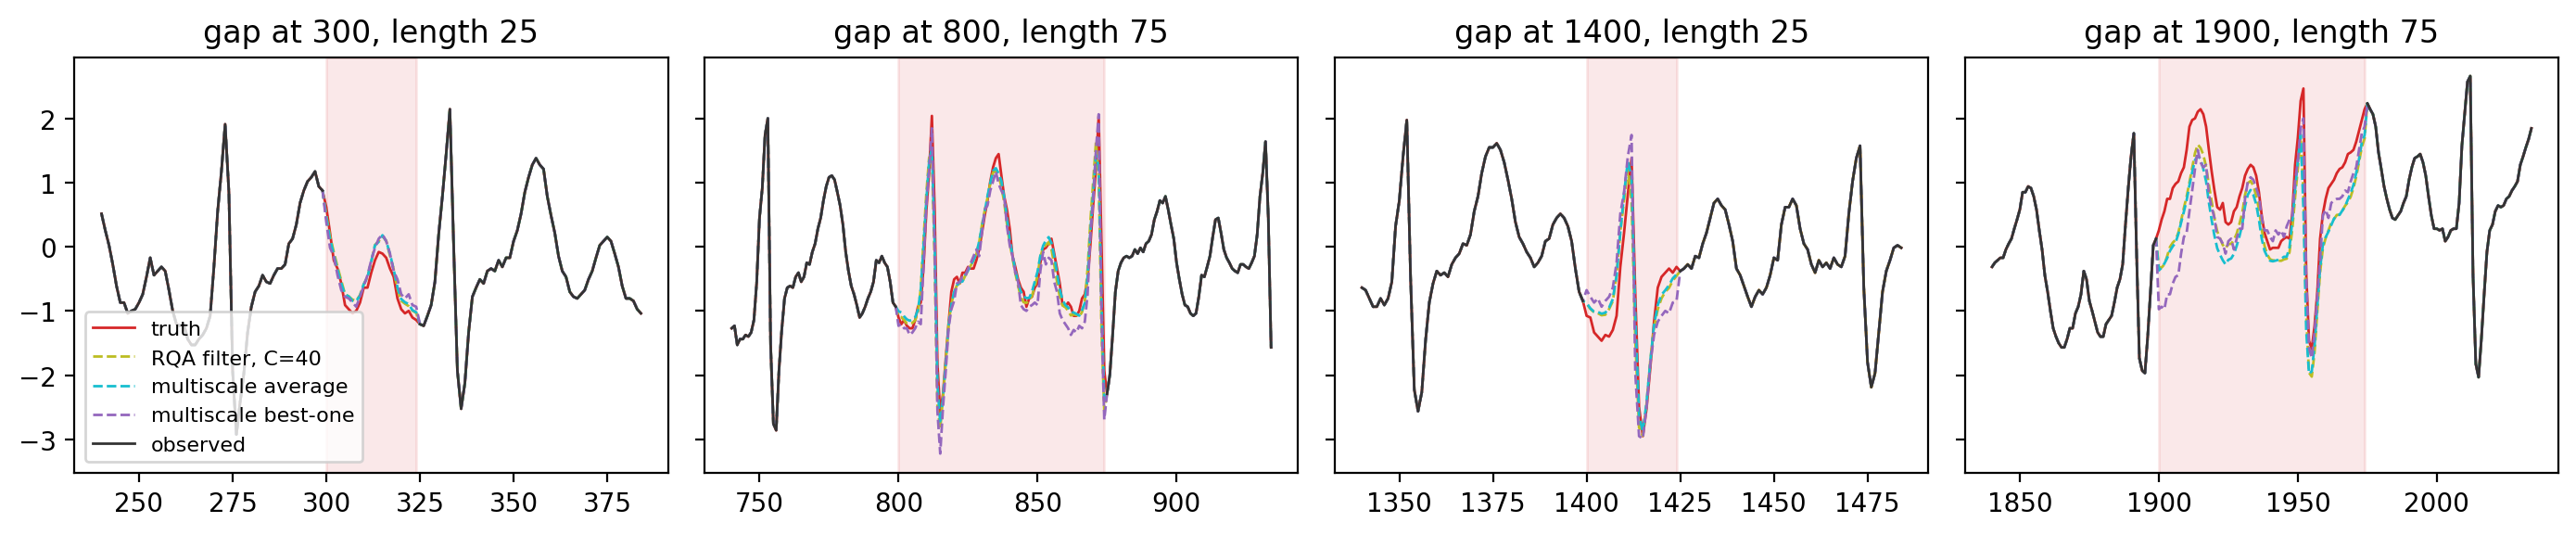

In [42]:
fig, axes = plt.subplots(1, len(gaps), figsize=(14, 3), sharey=True)
for ax, (start, length) in zip(axes, gaps):
    w = slice(start - 60, start + length + 60)   # gap plus 60 samples each side
    ax.plot(idx[w], truth[w], color="tab:red", lw=1, label="truth")
    ax.plot(idx[w], rec_rqa_own_fill[w], color="tab:olive", lw=1, ls="--", label="RQA filter, C=40")
    ax.plot(idx[w], ms_avg_fill[w], color="tab:cyan", lw=1, ls="--", label="multiscale average")
    ax.plot(idx[w], ms_best_fill[w], color="tab:purple", lw=1, ls="--", label="multiscale best-one")
    ax.plot(idx[w], obs[w], color="0.2", lw=1, label="observed")
    ax.axvspan(start, start + length - 1, color="tab:red", alpha=0.1)
    ax.set_title(f"gap at {start}, length {length}")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

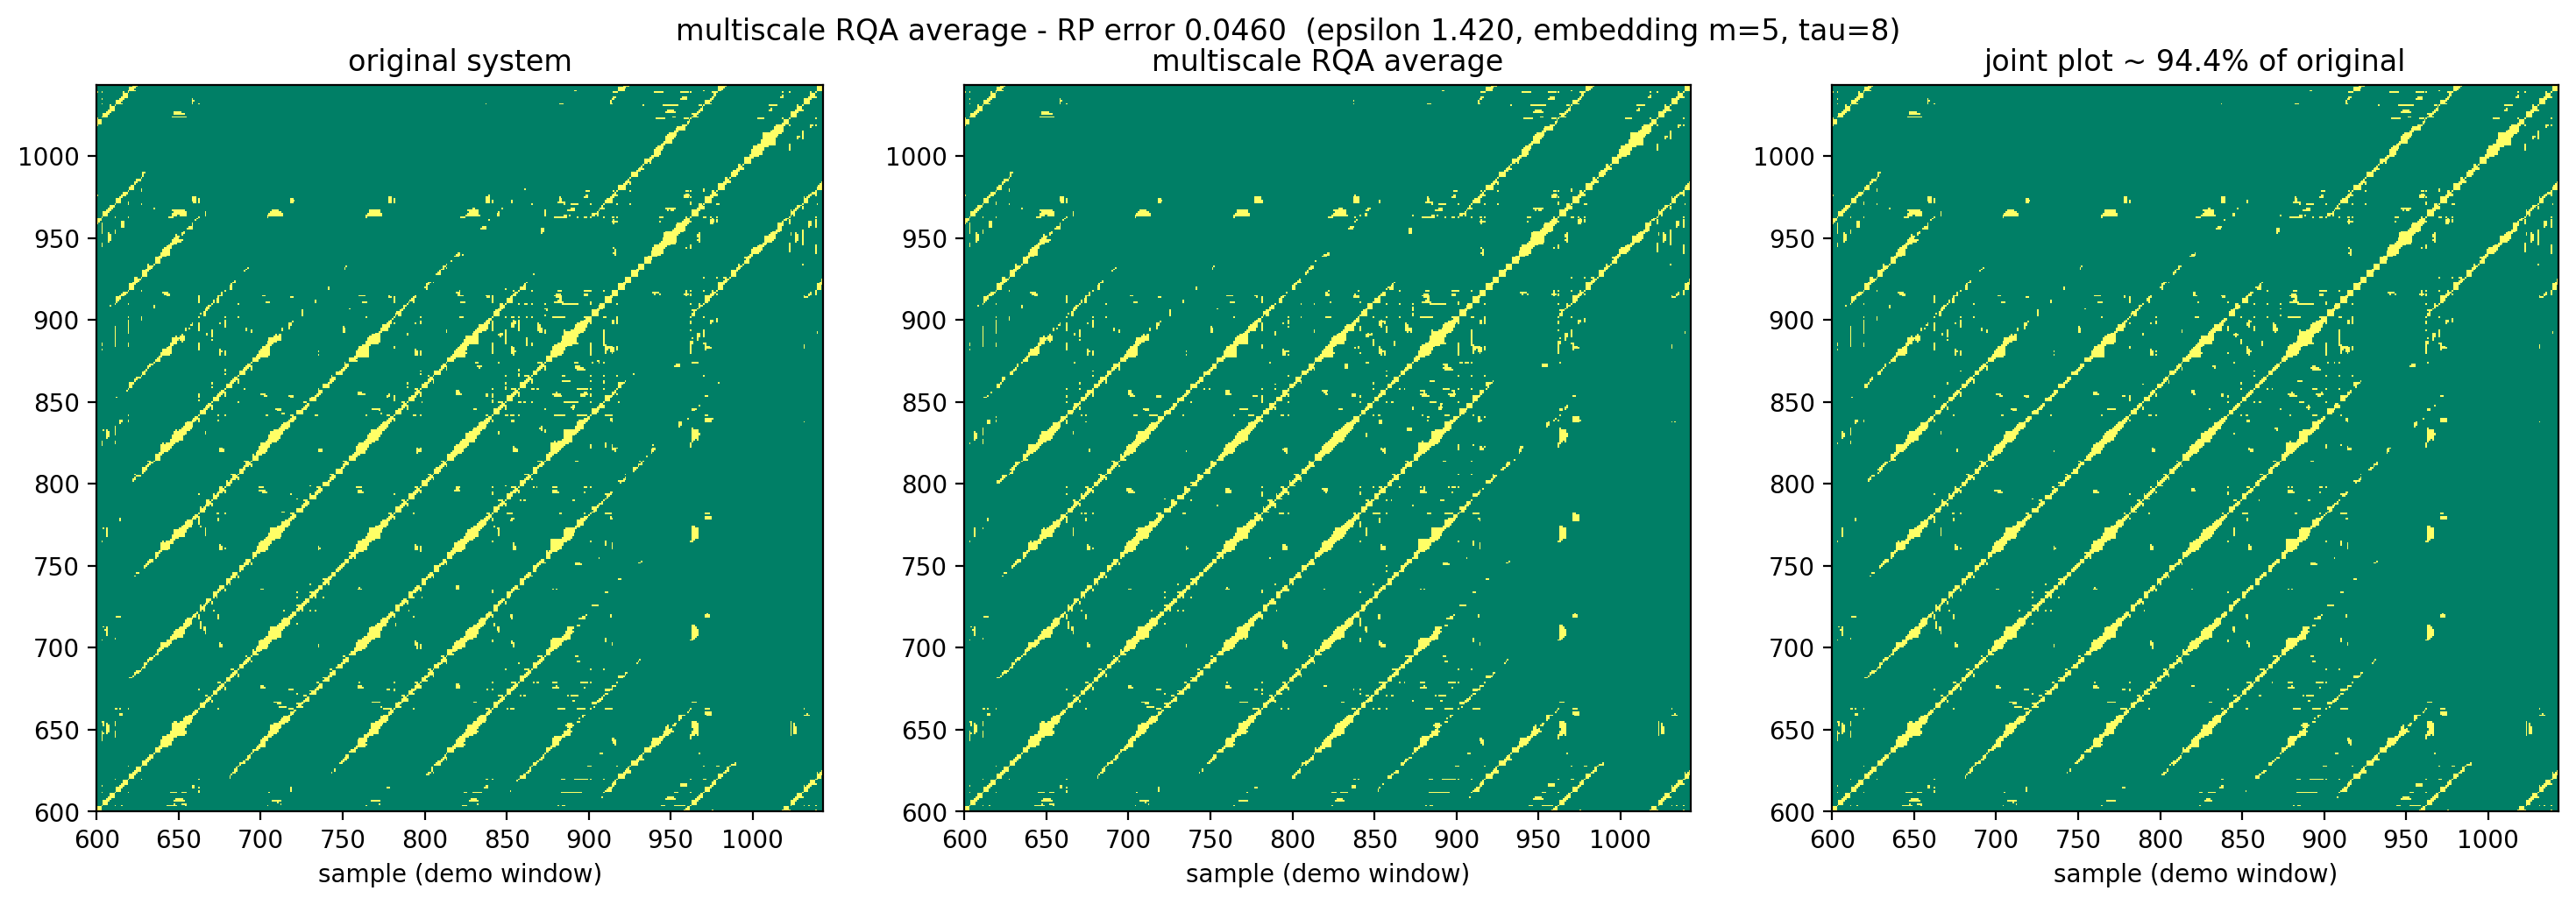

In [43]:
plot_rp_comparison("multiscale RQA average", ms_avg_fill)

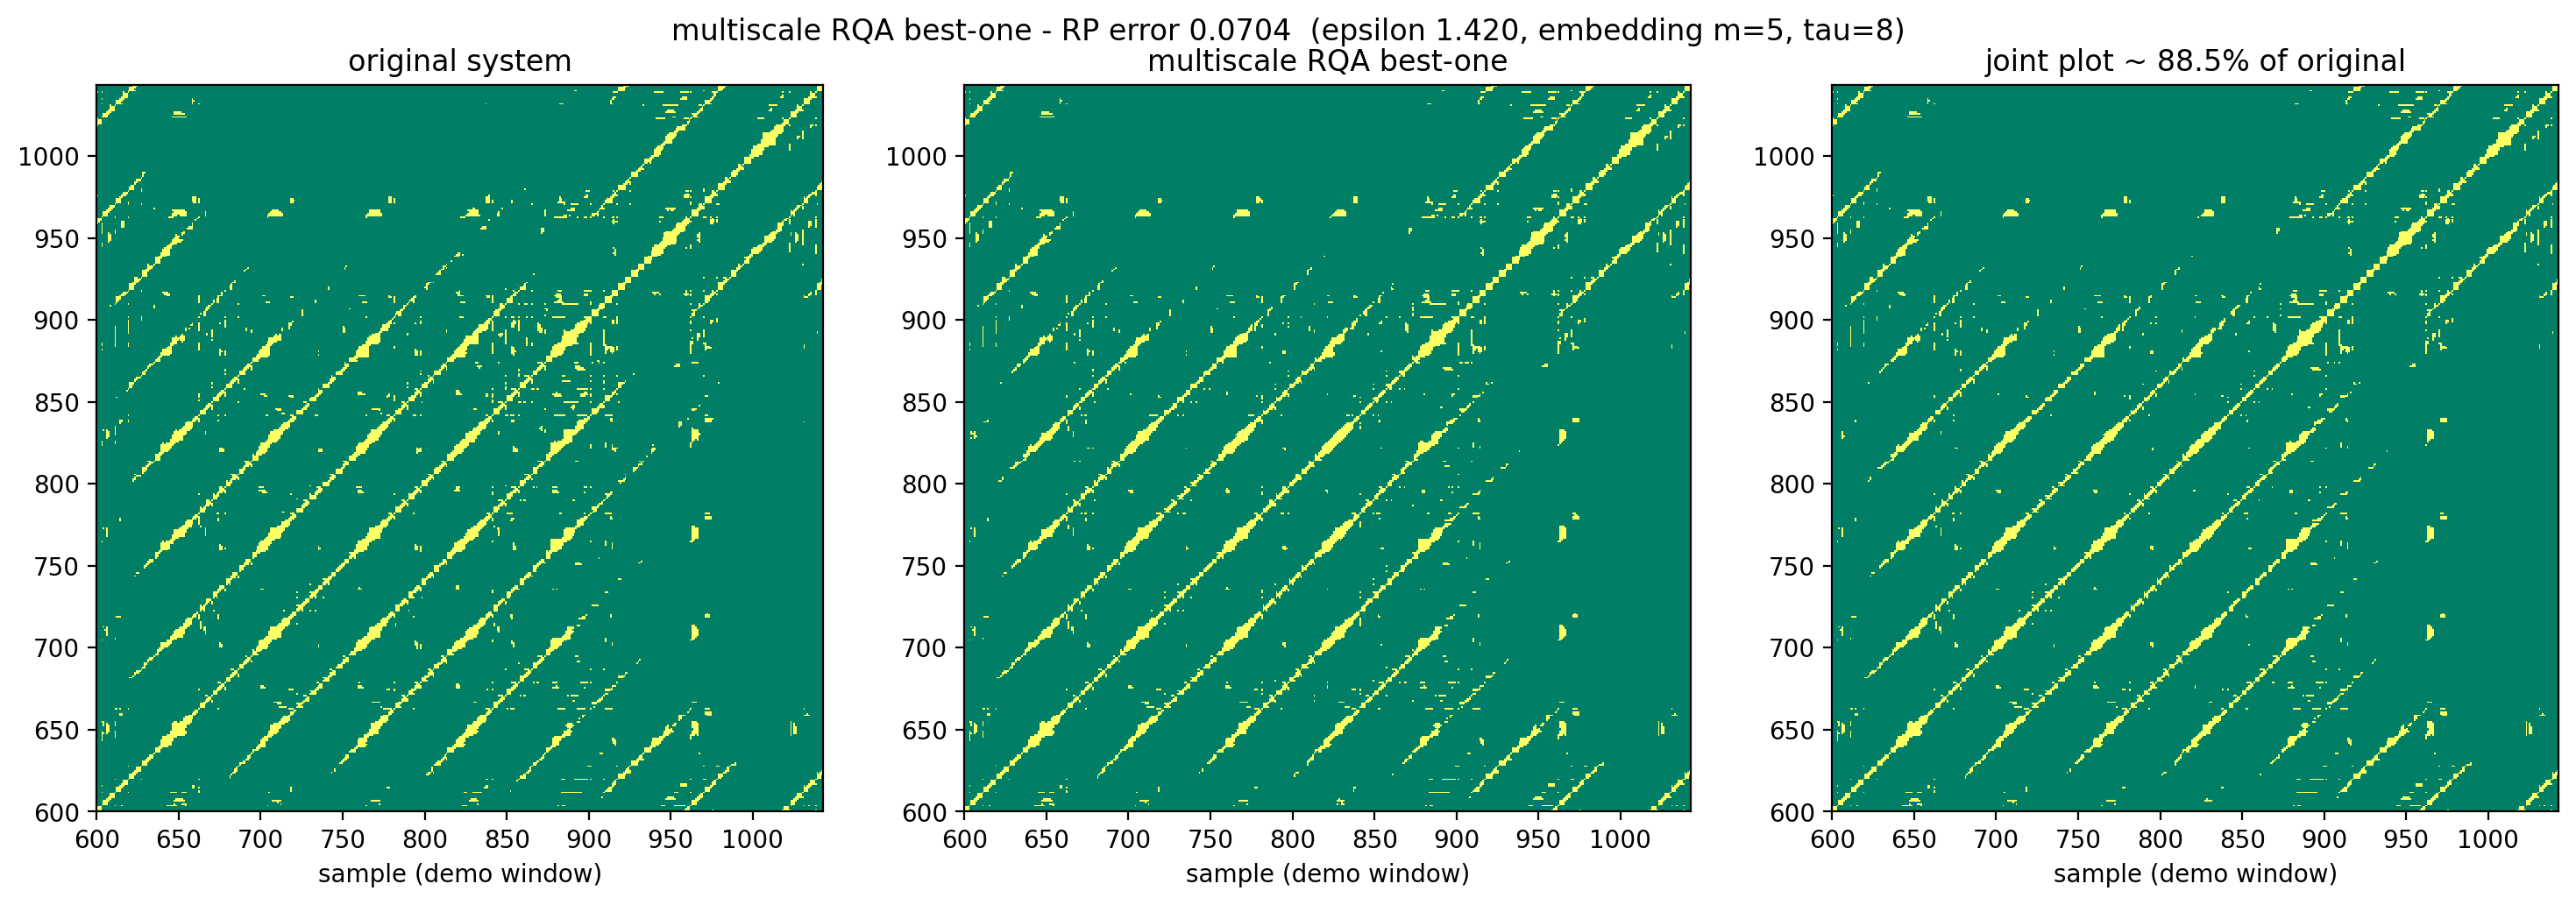

In [44]:
plot_rp_comparison("multiscale RQA best-one", ms_best_fill)

In [45]:
pd.DataFrame(results).T.round(3)

,MAE,RP error
linear,1.003,0.170
spline,1.661,0.391
bousse,0.824,0.142
recurrence (own channel),0.335,0.062
recurrence (+ helper),0.271,0.054
recurrence (own channel) + RQA filter,0.319,0.061
recurrence (+ helper) + RQA filter,0.244,0.051
multiscale RQA average (own channel),0.326,0.064
multiscale RQA best-one (own channel),0.363,0.064
